# [16.9] Data Shapley in One Training Run (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part9_data_shapley/16.9_Data_Shapley_in_One_Training_Run_exercises.ipynb) | [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter16_shapley_attribution_baselines/exercises/part9_data_shapley/16.9_Data_Shapley_in_One_Training_Run_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-03.png" width="350">

# Introduction

Here is a small experiment. We take 128 handwritten digits, half of them 1s and half of them 7s, and train a tiny neural network to tell them apart. Before training, we secretly flip the labels of 12 of the images, so that six 1s are labelled "7" and six 7s are labelled "1". The trained network still classifies 63 of the 64 test images correctly, with a test loss of 0.149. If we switch off the 12 mislabelled images and rerun exactly the same training, it gets all 64 right and the test loss drops to 0.057.

Now suppose you didn't know which 12 images were mislabelled. Could you find them by asking the trained model *which of its training examples helped it, and which ones hurt?*

This is the question of **data attribution** (or **data valuation**), and it matters well beyond toy digit classifiers. Which documents in a pretraining corpus actually make a language model better? Which examples in a fine-tuning set are responsible for a bad behaviour? If a model reproduces copyrighted text, which training data does it owe that to? Interpretability usually asks which *activations* or *components* cause an output; data attribution asks which *training data* caused the model to be the way it is.

The most principled answer comes from cooperative game theory. **Data Shapley** (Ghorbani & Zou, 2019) treats every training example as a player in a game whose payoff is the performance of a model trained on a set of players, and gives each example its Shapley value: its average marginal contribution, over all the ways the dataset could have been assembled. It has exactly the properties you'd want from a fair credit assignment. The catch is that computing it requires training a model on many (in principle, all $2^n$) subsets of the data.

**In-Run Data Shapley** (Wang, Mittal, Song & Jia, ICLR 2025) changes the question slightly, in a way that makes it almost free to answer. Instead of asking about every possible training run, it asks how much each example contributed to *this particular* training run, one gradient step at a time. With a first-order Taylor expansion, each step's contribution is a dot product between a training example's gradient and the validation gradient; with a trick called the **ghost dot product**, all of these dot products can be computed during the ordinary backward pass without ever storing a per-example gradient. The authors used it to attribute the pretraining data of GPT-2-sized models, something retraining-based methods could never do.

By the end of this section you'll have built all of it from scratch, on problems small enough that we can check every answer:

- exact Data Shapley by training a model on all 256 subsets of an 8-point dataset;
- Monte Carlo and truncated Monte Carlo estimators, and how much accuracy you buy per model trained;
- per-example gradients, by writing the backward pass of an MLP by hand, and the ghost dot product identity that avoids materialising them;
- In-Run Data Shapley with first-order, second-order and exact per-step credit, accumulated over a real SGD run on the digits;
- and a validation of all of it: against exact values on the toy problem, against 25,600-training-run Monte Carlo Data Shapley on the digits, and against the ground truth of actually deleting data and retraining.

We'll pay particular attention to **controls**. Every attribution score in this notebook is compared against randomly chosen points, against scores computed for the wrong target (shuffled validation labels), and against cheap baselines like leave-one-out. Some of the results are not flattering to the method you're implementing. On our digits, first-order In-Run credit claims about 2.5 times more improvement than actually happened; plain leave-one-out finds the flipped labels about as well as In-Run credit does; and on the examples that *aren't* mislabelled, In-Run credit and retraining-based Data Shapley mostly disagree about which ones matter. Those findings are part of the lesson, so we'll keep them in plain view.

This section assumes you know what a Shapley value is (section [16.1] covers this from scratch; we'll recap what we need), and that you're comfortable with SGD and backpropagation at the level of [0.3] Optimization and [0.4] Backprop. Everything runs on a CPU in about a minute, using float64 so that our identity checks hold to many decimal places.

## Content & Learning Objectives

### 1️⃣ Data Shapley by Retraining

You'll define data valuation as a cooperative game, implement a learning algorithm that can be run on any subset of the data, and compute exact Data Shapley values on an 8-point logistic regression problem with a duplicated point, a mislabelled point and a rare point, by training 256 models. You'll compare against leave-one-out and check that the negative credit follows the bad label when we move it.

> ##### Learning Objectives
>
> - Understand data valuation as a cooperative game, and why Data Shapley is always defined *relative to a learning algorithm and a utility*
> - Implement exact Data Shapley by enumerating and training on every subset, and check efficiency and symmetry
> - See why leave-one-out undervalues duplicated data, and use a label-relocation control to confirm what the values are measuring

### 2️⃣ Monte Carlo Data Shapley

Exact Data Shapley is exponential in the number of examples. You'll implement the permutation-sampling Monte Carlo estimator and its truncated variant (TMC-Shapley), and measure how the error falls with the number of models trained, and what truncation costs in bias.

> ##### Learning Objectives
>
> - Implement Monte Carlo Data Shapley by sampling random orderings of the data
> - Implement truncated Monte Carlo, and understand the bias/compute trade-off of truncation
> - Measure estimation error against the number of models trained, and compare against exact enumeration and leave-one-out

### 3️⃣ Per-Example Gradients and Ghost Dot Products

In-Run Data Shapley needs dot products between per-example gradients. You'll write the forward and backward pass of an MLP by hand so you can see exactly where per-example gradients come from, derive the **ghost dot product** identity that computes their dot products without materialising them, and use it to see what training examples are "saying" to the validation set at the start and end of training.

> ##### Learning Objectives
>
> - Express each layer's per-example weight gradient as an outer product of the layer's input and its output gradient
> - Implement the ghost dot product $\langle a_i^\top d_i, a_j^\top d_j \rangle = (a_i \cdot a_j)(d_i \cdot d_j)$, including bias terms, and check it against autograd
> - Measure how its cost scales with model size compared with materialising gradients

### 4️⃣ In-Run Data Shapley

You'll define the per-step **local game** that In-Run Data Shapley allocates, compute its exact Shapley values by brute force, derive and implement the first- and second-order approximations, and accumulate all three over a real SGD run. You'll validate them on the toy problem against exact Data Shapley, and on the digits by checking whether the credit adds up to what actually happened.

> ##### Learning Objectives
>
> - Understand how In-Run Data Shapley decomposes a training run into per-step cooperative games, and why the per-step values telescope
> - Implement first-order and second-order In-Run Data Shapley using ghost dot products and a Hessian-vector product
> - Measure how far the first-order approximation is from the exact per-step values, and when it matters

### 5️⃣ Does the Credit Mean Anything?

Finally, you'll compare In-Run credit with Monte Carlo Data Shapley computed from 25,600 training runs, and test every method with the experiment that matters: delete the lowest- or highest-credit examples, retrain, and measure test loss, against matched random deletions, three training seeds and a shuffled-label control.

> ##### Learning Objectives
>
> - Vectorise Monte Carlo Data Shapley over prefixes, and simulate truncation exactly from the results
> - Implement deletion experiments with matched random controls, and evaluate attribution methods by what deleting data actually does
> - Report where cheap and expensive methods agree, where they disagree, and which differences are real

### ☆ Bonus

Extensions and open questions, including how the SGD derivation breaks under Adam (and the 2026 Adam-aware variant of In-Run Data Shapley), the connection to TracIn, and further reading.

## Setup code

In [ ]:
import os
import sys
#
IN_COLAB = "google.colab" in sys.modules
#
if IN_COLAB:
    # Install dependencies, and download this chapter's exercise files from the ARENA extension repo
    %pip install jaxtyping scikit-learn
    repo, branch, chapter = "ARENA_3.0_Extended", "main", "chapter16_shapley_attribution_baselines"
    if not os.path.exists(f"/content/{chapter}"):
        !wget -P /content https://github.com/shinobiultra/{repo}/archive/refs/heads/{branch}.zip
        !unzip -q /content/{branch}.zip '{repo}-{branch}/{chapter}/exercises/*' -d /content
        !mv /content/{repo}-{branch}/{chapter} /content/{chapter}
        !rm -r /content/{branch}.zip /content/{repo}-{branch}
    os.chdir(f"/content/{chapter}/exercises")

In [ ]:
import itertools
import math
import sys
import time
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
import torch.nn.functional as F
from IPython.display import display
from jaxtyping import Float, Int
from torch import Tensor
from tqdm.auto import tqdm

# Everything in this section is small enough to run on a CPU. We use float64 so that the identities we check
# (Shapley efficiency, ghost dot products vs autograd, telescoping sums) hold to ~12 decimal places, and a single
# thread because our tensors are tiny (multi-threading only adds overhead, especially on a shared machine).
t.set_default_dtype(t.float64)
t.set_num_threads(1)

# Make sure exercises are in the path
chapter = "chapter16_shapley_attribution_baselines"
section = "part9_data_shapley"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part9_data_shapley.tests as tests
import part9_data_shapley.utils as utils

Coalition = frozenset[int]  # a set of training-example indices
Params = list[tuple[Tensor, Tensor]]  # one (weight, bias) pair per layer

MAIN = __name__ == "__main__"

# 1️⃣ Data Shapley by Retraining

> ##### Learning Objectives
>
> - Understand data valuation as a cooperative game, and why Data Shapley is always defined *relative to a learning algorithm and a utility*
> - Implement exact Data Shapley by enumerating and training on every subset, and check efficiency and symmetry
> - See why leave-one-out undervalues duplicated data, and use a label-relocation control to confirm what the values are measuring

## Data valuation as a cooperative game

Suppose we have a training set $D = \{z_1, \dots, z_n\}$, a learning algorithm $\mathcal{A}$ that turns any subset $S \subseteq D$ into a trained model $\mathcal{A}(S)$, and a way of scoring a model, for example its loss on a held-out validation set. Together these define a **utility function** on subsets of the data:

$$
v(S) = L_{val}\big(\mathcal{A}(\varnothing)\big) - L_{val}\big(\mathcal{A}(S)\big)
$$

i.e. how much training on $S$ improves validation loss, compared to not training at all. (We use loss *improvement* throughout this section, so that positive credit means "helpful". The In-Run Data Shapley paper uses the opposite sign convention, loss *change*, so be careful when comparing equations.)

This is a cooperative game in exactly the sense of section [16.1]: the training examples are the players, and $v(S)$ is the payoff when the players in $S$ "work together". The **Data Shapley value** of example $i$ is its Shapley value in this game,

$$
\phi_i = \sum_{S \subseteq D \setminus \{i\}} \frac{|S|!\,(n - |S| - 1)!}{n!} \Big[ v(S \cup \{i\}) - v(S) \Big],
$$

the average of its marginal contribution $v(S \cup \{i\}) - v(S)$ over all orderings in which the dataset could have been assembled. The Shapley axioms translate into very natural requirements on a data valuation:

- **Efficiency**: $\sum_i \phi_i = v(D)$. The values split up exactly the improvement the full dataset produced.
- **Symmetry**: two examples that contribute identically to every subset get the same value. In particular, exact duplicates get equal credit.
- **Null player**: an example that never changes the utility gets zero.
- **Linearity**: the value for a sum of two utilities (e.g. two validation sets) is the sum of the values.

It's worth stressing what Data Shapley is *not*. It isn't a property of an example on its own: it depends on the rest of the dataset, on the learning algorithm (architecture, optimiser, learning rate, number of steps, initialisation) and on the utility (which validation set, which metric). Change any of them and the values change. You'll see this concretely in the "Try it yourself" cell at the end of this section, and again in section 4️⃣, where In-Run Data Shapley changes the question in a subtle but important way.

## A toy problem with known answers

We'll start with a problem small enough to enumerate: 8 training points in 2D, and a logistic regression classifier. The points were chosen so that we know, before computing anything, roughly what a good valuation should say about some of them:

- Points **0 and 1** are exact duplicates (same features, same label). Symmetry says they must get equal credit.
- Point **6** sits at exactly the same location as points 0 and 1, but with the *opposite* label. It's a mislabelled copy, and it should be harmful.
- Point **7** is a positive example in an unusual place, far from the other positives. It's less obviously useful.

The validation set is 8 clean points, 4 of each class.

In [ ]:
TOY_X = t.tensor([[2.0, 1.0], [2.0, 1.0], [1.5, 1.5], [2.0, -0.5], [-2.0, -1.0], [-1.5, -1.5], [2.0, 1.0], [0.2, 2.5]])
TOY_Y = t.tensor([1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 1.0])
TOY_NAMES = [
    "duplicate A", "duplicate A (copy)", "positive, diagonal", "positive, low",
    "negative", "negative, diagonal", "MISLABELLED copy of A", "rare positive",
]
TOY_VAL_X = t.tensor([[2.0, 1.0], [1.5, 1.2], [2.0, -0.5], [1.0, 2.0], [-2.0, -1.0], [-1.5, -1.2], [-2.0, 0.5], [-1.0, -2.0]])
TOY_VAL_Y = t.tensor([1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0])

# The learning algorithm: zero initialisation, 40 steps of full-batch gradient descent with learning rate 0.2
TOY_STEPS, TOY_LR = 40, 0.2


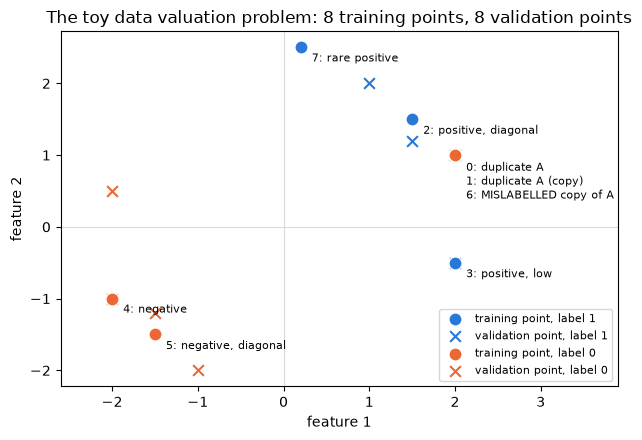

In [ ]:
utils.plot_toy_problem(TOY_X, TOY_Y, TOY_VAL_X, TOY_VAL_Y, TOY_NAMES)

### What does "training on a subset" mean?

Data Shapley needs a learning algorithm we can run on *any* subset $S$, including the empty set and single points. We have to make a choice about how the loss is normalised. There are two natural options:

1. Average the loss over the examples in $S$: $\frac{1}{|S|}\sum_{i \in S} \ell_i$. Then a model trained on 2 points takes steps as large as one trained on 8.
2. Sum the loss over $S$ but keep dividing by the full dataset size $n$: $\frac{1}{n}\sum_{i \in S} \ell_i$. This is what you get if you take the full training run and simply *switch off* the gradients of the examples not in $S$.

Both are legitimate, and they define different games with different Shapley values. We'll use **option 2 (a fixed denominator)** throughout this notebook, for one reason: it's the convention In-Run Data Shapley uses, where removing an example from a minibatch means "this example's gradient never gets added to the update", not "the other examples get a bigger learning rate". Using the same convention everywhere means every game in this notebook is about the same learning algorithm. (You can try option 1 in the "Try it yourself" cell at the end of this section.)

### Exercise - train a model on a coalition

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `train_on_subset`, which trains a logistic regression classifier $p(y = 1 \mid x) = \sigma(x^\top w + b)$ on the examples in `coalition`, and `subset_utility`, which returns the validation loss improvement $v(S)$.

The learning algorithm is:

- start from $w = 0$ (shape `(d,)`) and $b = 0$ (a scalar tensor of shape `()`);
- take `steps` steps of full-batch gradient descent on $\frac{1}{n}\sum_{i \in S} \text{BCE}(x_i^\top w + b, y_i)$, where $n$ is the total number of training examples (not $|S|$);
- return `(w, b)`.

The gradient of the binary cross-entropy with respect to the logit $s_i = x_i^\top w + b$ is $\sigma(s_i) - y_i$, so you don't need autograd: the gradient for $w$ is $\frac{1}{n}\sum_{i\in S} (\sigma(s_i) - y_i)\, x_i$ and for $b$ it's $\frac{1}{n}\sum_{i\in S} (\sigma(s_i) - y_i)$. A clean way to implement "sum over $S$" is to multiply the errors by a 0/1 mask.

For `subset_utility`, use `F.binary_cross_entropy_with_logits` (which averages over the validation set) and return a Python float. Note that the untrained model ($w = 0$, $b = 0$) predicts 0.5 for everything, so $v(\varnothing) = 0$.

In [ ]:
def train_on_subset(
    x: Float[Tensor, "n d"], y: Float[Tensor, " n"], coalition: Coalition, steps: int = TOY_STEPS, lr: float = TOY_LR
) -> tuple[Float[Tensor, " d"], Float[Tensor, ""]]:
    """
    Trains logistic regression from zero init with full-batch GD on the examples in `coalition`, using the
    fixed denominator n = len(x). Returns (w, b).
    """
    raise NotImplementedError()


def subset_utility(
    coalition: Coalition,
    x: Float[Tensor, "n d"],
    y: Float[Tensor, " n"],
    val_x: Float[Tensor, "m d"],
    val_y: Float[Tensor, " m"],
    steps: int = TOY_STEPS,
    lr: float = TOY_LR,
) -> float:
    """Returns v(S): validation loss of the untrained model minus validation loss after training on S."""
    raise NotImplementedError()


tests.test_train_on_subset(train_on_subset)
tests.test_subset_utility(subset_utility)

<details>
<summary>Hint</summary>

Build `mask = t.zeros(n)` and set `mask[list(coalition)] = 1.0`. Then each step is

```python
errors = (t.sigmoid(x @ w + b) - y) * mask
w = w - lr * x.T @ errors / n
b = b - lr * errors.sum() / n
```

Write the updates out-of-place (`w = w - ...`) rather than in-place, so you never accidentally modify a tensor you've returned earlier.
</details>


<details><summary>Solution</summary>

```python
def train_on_subset(
    x: Float[Tensor, "n d"], y: Float[Tensor, " n"], coalition: Coalition, steps: int = TOY_STEPS, lr: float = TOY_LR
) -> tuple[Float[Tensor, " d"], Float[Tensor, ""]]:
    """
    Trains logistic regression from zero init with full-batch GD on the examples in `coalition`, using the
    fixed denominator n = len(x). Returns (w, b).
    """
    n = len(x)
    mask = t.zeros(n)
    mask[list(coalition)] = 1.0
    w, b = t.zeros(x.shape[1]), t.zeros(())
    for _ in range(steps):
        errors = (t.sigmoid(x @ w + b) - y) * mask
        w = w - lr * x.T @ errors / n
        b = b - lr * errors.sum() / n
    return w, b


def subset_utility(
    coalition: Coalition,
    x: Float[Tensor, "n d"],
    y: Float[Tensor, " n"],
    val_x: Float[Tensor, "m d"],
    val_y: Float[Tensor, " m"],
    steps: int = TOY_STEPS,
    lr: float = TOY_LR,
) -> float:
    """Returns v(S): validation loss of the untrained model minus validation loss after training on S."""
    w, b = train_on_subset(x, y, coalition, steps, lr)
    loss_before = F.binary_cross_entropy_with_logits(t.zeros(len(val_y)), val_y)
    loss_after = F.binary_cross_entropy_with_logits(val_x @ w + b, val_y)
    return (loss_before - loss_after).item()
```
</details>

Let's look at a few coalitions. Before running the cell, predict the sign of each one.

In [ ]:
def toy_v(coalition: Coalition, y: Tensor = TOY_Y) -> float:
    """The toy game: train on `coalition` of the 8 toy points, return the validation loss improvement."""
    return subset_utility(coalition, TOY_X, y, TOY_VAL_X, TOY_VAL_Y)

In [ ]:
for coalition in [(), (0,), (6,), (0, 6), (0, 1), (0, 1, 6), tuple(range(8))]:
    print(f"v({set(coalition) or '{}'}) = {toy_v(frozenset(coalition)):+.4f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">v({}) = +0.0000
v({0}) = +0.4145
v({6}) = -0.7591
v({0, 6}) = +0.0000
v({0, 1}) = +0.5055
v({0, 1, 6}) = +0.2079
v({0, 1, 2, 3, 4, 5, 6, 7}) = +0.5082</pre>

</details>

A few things to notice. Training on the mislabelled point alone is very harmful. Training on point 0 *and* its mislabelled copy 6 gives exactly zero: their gradients are equal and opposite at every step (at the same $x$, $\sigma(s) - 1$ and $\sigma(s) - 0$ cancel when $\sigma(s) = 0.5$, which is where the model starts and stays). And adding the mislabelled point to the two duplicates more than halves their benefit. The marginal contribution of point 6 clearly depends on who else is in the coalition, which is exactly why we need to average over coalitions.

### Exercise - exact Data Shapley

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15 minutes on this exercise.
> ```

Implement `exact_data_shapley`. It takes a utility function on coalitions (`frozenset`s of indices) and the number of players $n$, and should:

1. evaluate the utility on **every** subset of `range(n)` exactly once, storing the results in a dict keyed by `frozenset`;
2. compute each player's Shapley value from the formula above, using the stored values.

Return both the values (a tensor of shape `(n,)`) and the dict of coalition values, which we'll reuse later.

The weight $\frac{|S|!(n-|S|-1)!}{n!}$ can be written as $\frac{1}{n \binom{n-1}{|S|}}$, which is easier to compute with `math.comb`. You may have written something very similar in [16.1]; the only difference here is that each utility evaluation trains a model, so we're careful to evaluate each coalition once.

In [ ]:
def exact_data_shapley(utility_fn: Callable[[Coalition], float], n: int) -> tuple[Float[Tensor, " n"], dict[Coalition, float]]:
    """
    Computes exact Shapley values by evaluating `utility_fn` on all 2^n coalitions.
    Returns (values, table) where table maps every coalition to its utility.
    """
    raise NotImplementedError()


tests.test_exact_data_shapley(exact_data_shapley)

<details>
<summary>Hint</summary>

`itertools.combinations(range(n), size)` for `size` in `range(n + 1)` enumerates every subset. For the values, loop over players `i`, then over subsets `S` of the *other* players, and add `weight * (table[S | {i}] - table[S])`.
</details>

<details>
<summary>Help - the test says my values don't match the permutation oracle.</summary>

The test checks your function against the definition of the Shapley value as an average over all $n!$ orderings, on a few small games. The most common mistake is the weight: it should be $\frac{1}{n\binom{n-1}{|S|}}$ where $|S|$ is the size of the coalition *without* player $i$. Another is enumerating coalitions that already contain $i$.
</details>


<details><summary>Solution</summary>

```python
def exact_data_shapley(utility_fn: Callable[[Coalition], float], n: int) -> tuple[Float[Tensor, " n"], dict[Coalition, float]]:
    """
    Computes exact Shapley values by evaluating `utility_fn` on all 2^n coalitions.
    Returns (values, table) where table maps every coalition to its utility.
    """
    table = {
        frozenset(c): utility_fn(frozenset(c)) for size in range(n + 1) for c in itertools.combinations(range(n), size)
    }
    values = t.zeros(n)
    for i in range(n):
        others = [j for j in range(n) if j != i]
        for size in range(n):
            weight = 1 / (n * math.comb(n - 1, size))
            for c in itertools.combinations(others, size):
                coalition = frozenset(c)
                values[i] += weight * (table[coalition | {i}] - table[coalition])
    return values, table
```
</details>

Now let's compute the exact Data Shapley values of our 8 points. This trains 256 logistic regression models, which takes a second or less.

In [ ]:
t0 = time.time()
toy_exact, toy_table = exact_data_shapley(toy_v, 8)
full = frozenset(range(8))
print(f"Trained {len(toy_table)} models in {time.time() - t0:.1f}s\n")
for i, name in enumerate(TOY_NAMES):
    print(f"{i}  {name:<24} {toy_exact[i]:+.4f}")
print(f"\nsum of values = {toy_exact.sum():.4f},   v(full dataset) = {toy_table[full]:.4f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Trained 256 models in 0.1s

0  duplicate A              +0.1309
1  duplicate A (copy)       +0.1309
2  positive, diagonal       +0.1164
3  positive, low            +0.1175
4  negative                 +0.1480
5  negative, diagonal       +0.1352
6  MISLABELLED copy of A    -0.3278
7  rare positive            +0.0572

sum of values = 0.5082,   v(full dataset) = 0.5082</pre>

</details>

The values do what we hoped: the duplicates are tied, the mislabelled point gets a large negative value, the rare positive is the least valuable of the helpful points, and the values sum to $v(D)$ (efficiency).

### Exercise - leave-one-out

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

The simplest data valuation of all is **leave-one-out (LOO)**: how much worse does the model get if we remove example $i$ from the full dataset?

$$
\text{LOO}_i = v(D) - v(D \setminus \{i\})
$$

LOO needs only $n + 1$ trainings rather than $2^n$, and it's what most people mean when they talk informally about "the effect of a training example". It is also the marginal contribution of $i$ in just one of the $2^{n-1}$ coalitions that Data Shapley averages over: the biggest one. Implement it.

In [ ]:
def leave_one_out(utility_fn: Callable[[Coalition], float], n: int) -> Float[Tensor, " n"]:
    """Returns v(D) - v(D minus i) for every i."""
    raise NotImplementedError()


tests.test_leave_one_out(leave_one_out)

<details><summary>Solution</summary>

```python
def leave_one_out(utility_fn: Callable[[Coalition], float], n: int) -> Float[Tensor, " n"]:
    """Returns v(D) - v(D minus i) for every i."""
    everyone = frozenset(range(n))
    v_full = utility_fn(everyone)
    return t.tensor([v_full - utility_fn(everyone - {i}) for i in range(n)])
```
</details>

We'll compute LOO by looking values up in the table we already have (no new training needed), and then add a **control**. If the negative value of point 6 really comes from its *label* rather than from anything about its position in the list or its features, then moving the bad label should move the negative value with it. So we swap the labels of points 0 and 6: now point 0 is the mislabelled copy and point 6 is the correct one. Everything else (features, validation set, learning algorithm) is unchanged. This trains another 256 models.


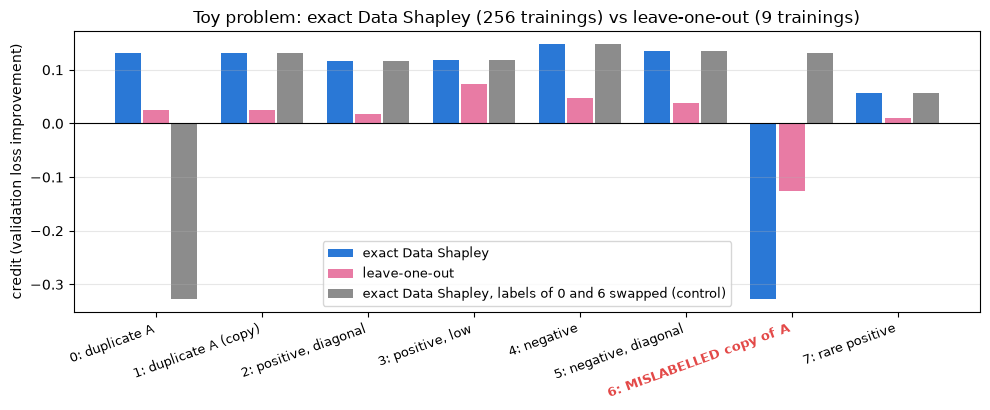

In [ ]:
toy_loo = leave_one_out(lambda S: toy_table[S], 8)

swapped_y = TOY_Y[[6, 1, 2, 3, 4, 5, 0, 7]]  # swap the labels of points 0 and 6
toy_exact_swapped, _ = exact_data_shapley(lambda S: toy_v(S, swapped_y), 8)

utils.plot_value_bars(
    {
        "exact Data Shapley": toy_exact,
        "leave-one-out": toy_loo,
        "exact Data Shapley, labels of 0 and 6 swapped (control)": toy_exact_swapped,
    },
    [f"{i}: {name}" for i, name in enumerate(TOY_NAMES)],
    "Toy problem: exact Data Shapley (256 trainings) vs leave-one-out (9 trainings)",
    colors=[utils.COLORS["data_shapley"], utils.COLORS["loo"], utils.COLORS["control"]],
    highlight=[6],
)
print("LOO:", [round(v, 4) for v in toy_loo.tolist()])

<details>
<summary>Help - how should I interpret this plot?</summary>

**Exact Data Shapley (blue)** is what we saw above: the duplicates are tied at 0.131, the mislabelled copy is strongly negative (-0.328), the rare positive is the least valuable helpful point (0.057), and the values add up to $v(D) = 0.508$.

**Leave-one-out (pink)** gets every *sign* right, but look at the scale. The LOO values add up to only 0.110, a fifth of $v(D)$: LOO doesn't satisfy efficiency, because it only measures what each point adds *on top of everything else*, and most of what a point does can also be done by other points. The clearest case is the duplicates. Each gets an LOO value of 0.025, less than a fifth of its Data Shapley value, because when you remove one copy, the other copy is still there doing exactly the same job. Two copies of a useful example look nearly worthless to LOO; this is the standard argument for Data Shapley over leave-one-out in the data valuation literature. Conversely, point 3 has the *largest* LOO value (0.074): it's the only training point near the validation point at $(2, -0.5)$, so nothing can stand in for it. LOO ranks it first; Data Shapley ranks it fifth, behind both duplicates.

**The control (grey)** behaves exactly as it should. After swapping the labels of points 0 and 6, point 0 gets -0.328 and point 6 gets 0.131: the two values have swapped exactly, and nothing else has changed. That's because points 0 and 6 have identical features, so swapping their labels is just renaming two players. The negative value belongs to the bad label, not to a position in the list.
</details>

## Try it yourself - change the game

Data Shapley values are a property of the *whole game*: the data, the learning algorithm and the utility. Use the cell below to change one thing at a time and see how the values respond. Some ideas:

- Flip the label of the rare positive (point 7). Does it become harmful, or merely useless?
- Make point 7 a *third* duplicate of point 0 (same features, same label). What happens to the values of points 0, 1 and 7, and to their LOO values?
- Change the learning algorithm: use 400 steps instead of 40, or normalise by $|S|$ instead of $n$ (option 1 above) by editing `train_on_subset`. Which values change the most?

Each run trains 256 models, which only takes a moment.

In [ ]:
try_x, try_y = TOY_X.clone(), TOY_Y.clone()
try_y[7] = 0.0  # flip the label of the rare positive

try_values, try_table = exact_data_shapley(lambda S: subset_utility(S, try_x, try_y, TOY_VAL_X, TOY_VAL_Y), 8)
try_loo = leave_one_out(lambda S: try_table[S], 8)
display(
    pd.DataFrame(
        {"original Data Shapley": toy_exact, "new Data Shapley": try_values, "new LOO": try_loo},
        index=[f"{i}: {name}" for i, name in enumerate(TOY_NAMES)],
    ).round(4)
)

<details>
<summary>Expected output (for flipping the label of point 7)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                          original Data Shapley  new Data Shapley  new LOO
0: duplicate A                           0.1309            0.1595   0.0399
1: duplicate A (copy)                    0.1309            0.1595   0.0399
2: positive, diagonal                    0.1164            0.1689   0.0743
3: positive, low                         0.1175            0.0949   0.0114
4: negative                              0.1480            0.1583   0.0344
5: negative, diagonal                    0.1352            0.1680   0.0652
6: MISLABELLED copy of A                -0.3278           -0.3248  -0.1341
7: rare positive                         0.0572           -0.1548  -0.0691</pre>

With a flipped label, point 7 goes from slightly helpful (0.057) to clearly harmful (-0.155), although less harmful than the mislabelled copy of A (-0.325), whose label contradicts two other training points. Notice that the *other* values change too: since the values must add up to $v(D)$, and the game has changed, every example's share is recomputed. Point 2, the positive example nearest to point 7's region, becomes more valuable (0.116 to 0.169): with point 7 now pulling the wrong way there, point 2 is doing more of the work.
</details>

## Summary of 1️⃣

- Data Shapley values a training example by its average marginal contribution to a utility, over all subsets of the rest of the data. It's defined relative to a learning algorithm and a utility, and we've fixed both: zero init, a fixed number of gradient steps with a fixed denominator, and validation loss improvement.
- On a problem with 8 points we can compute it exactly, by training 256 models. The values satisfy efficiency and symmetry, give the mislabelled point a large negative value, and follow the bad label when we move it.
- Leave-one-out only looks at one coalition, the full dataset, and that's exactly where redundancy hides value: a duplicated point looks almost worthless because its copy can stand in for it.

The obvious problem is the $2^n$. For our 128 digits, $2^{128} \approx 3 \times 10^{38}$ trainings is not an option. The next section is about estimating Data Shapley with fewer trainings.

# 2️⃣ Monte Carlo Data Shapley

> ##### Learning Objectives
>
> - Implement Monte Carlo Data Shapley by sampling random orderings of the data
> - Implement truncated Monte Carlo, and understand the bias/compute trade-off of truncation
> - Measure estimation error against the number of models trained, and compare against exact enumeration and leave-one-out

## Sampling orderings instead of enumerating subsets

Recall the other way of writing the Shapley value: imagine the training examples arriving one at a time in a uniformly random order $\pi$. When example $i$ arrives, it joins the set $P_i^\pi$ of examples that arrived before it, and we credit it with its marginal contribution. The Shapley value is the expected credit:

$$
\phi_i = \mathbb{E}_{\pi}\Big[ v\big(P_i^\pi \cup \{i\}\big) - v\big(P_i^\pi\big) \Big]
$$

This suggests an obvious estimator. Sample $M$ random orderings. For each one, start from the empty set and add the examples one at a time, training a model at each step; the difference between consecutive utilities is the marginal contribution of the example just added. Average over orderings.

One ordering costs $n$ trainings and gives one marginal contribution for *every* example, so $M$ orderings cost $nM$ trainings. The estimator is unbiased, and by the central limit theorem its error falls like $1/\sqrt{M}$: to halve the error, you need four times as many trainings. This is the "Monte Carlo" (or permutation sampling) estimator of Data Shapley, from Ghorbani & Zou ([*Data Shapley: Equitable Valuation of Data for Machine Learning*](https://arxiv.org/abs/1904.02868), 2019) and Jia et al. ([*Towards Efficient Data Valuation Based on the Shapley Value*](https://arxiv.org/abs/1902.10275), 2019).

To see what each estimator *costs*, we'll wrap the utility function in a small class that counts how many times it's called. On the toy problem every coalition's utility is already in `toy_table`, so the "training" is a dictionary lookup, but we'll count each lookup as one training run, since that's what it would cost on a problem where we couldn't enumerate.

In [ ]:
class CountingUtility:
    """Wraps a utility function and counts how many times it's called (i.e. how many models would be trained)."""

    def __init__(self, utility_fn: Callable[[Coalition], float]):
        self.utility_fn = utility_fn
        self.calls = 0

    def __call__(self, coalition: Coalition) -> float:
        self.calls += 1
        return self.utility_fn(coalition)

### Exercise - Monte Carlo Data Shapley

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `mc_data_shapley`. To make results reproducible (and testable), use this exact recipe for randomness:

- create one generator, `gen = t.Generator().manual_seed(seed)`;
- draw each ordering with `t.randperm(n, generator=gen)`.

Call `utility_fn` once on the empty coalition at the start, and then exactly once each time you add an example to the coalition (so $1 + nM$ calls in total). Return the average marginal contribution of each example, a tensor of shape `(n,)`.

In [ ]:
def mc_data_shapley(utility_fn: Callable[[Coalition], float], n: int, n_permutations: int, seed: int = 0) -> Float[Tensor, " n"]:
    """Monte Carlo (permutation sampling) estimate of the Shapley values of `utility_fn`."""
    raise NotImplementedError()


tests.test_mc_data_shapley(mc_data_shapley)

<details>
<summary>Hint</summary>

For each ordering, keep track of the current coalition and its utility (`previous`). For each example `i` in the ordering, add it to the coalition, evaluate the new utility, credit `i` with the difference, and update `previous`.
</details>


<details><summary>Solution</summary>

```python
def mc_data_shapley(utility_fn: Callable[[Coalition], float], n: int, n_permutations: int, seed: int = 0) -> Float[Tensor, " n"]:
    """Monte Carlo (permutation sampling) estimate of the Shapley values of `utility_fn`."""
    gen = t.Generator().manual_seed(seed)
    totals = t.zeros(n)
    v_empty = utility_fn(frozenset())
    for _ in range(n_permutations):
        coalition, previous = frozenset(), v_empty
        for i in t.randperm(n, generator=gen).tolist():
            coalition = coalition | {i}
            current = utility_fn(coalition)
            totals[i] += current - previous
            previous = current
    return totals / n_permutations
```
</details>

## Truncation

Ghorbani & Zou made an observation that saves a lot of compute in practice. Once a coalition is large, adding one more example barely changes a trained model: the marginal contributions of the examples late in an ordering are tiny. So if the utility of the current coalition is already within some **tolerance** $\tau$ of the full dataset's utility $v(D)$, we can stop training and set the marginal contributions of all the remaining examples in that ordering to zero. This is **Truncated Monte Carlo Shapley** (TMC-Shapley).

Truncation is not free. It introduces a bias: the remaining examples' contributions aren't exactly zero, and summed over the rest of the ordering they add up to $v(D) - v(P)$, which can be as large as $\tau$. Unlike the Monte Carlo noise, this bias does not shrink as you sample more orderings.

### Exercise - truncated Monte Carlo

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `tmc_data_shapley`. Use the same randomness recipe as before. At the start, evaluate the utility of the empty coalition and of the full dataset (2 calls). Then for each ordering, before adding each example, check whether the current coalition's utility is within `tolerance` of $v(D)$, i.e. `abs(v_full - previous) < tolerance`. If it is, the example's marginal contribution is zero and you don't call `utility_fn`; since nothing changes, the same will be true for every later example in this ordering, so you can stop. Otherwise, proceed as in `mc_data_shapley`.

With `tolerance=0`, your function should give exactly the same values as `mc_data_shapley` (with two more utility calls).

In [ ]:
def tmc_data_shapley(
    utility_fn: Callable[[Coalition], float], n: int, n_permutations: int, tolerance: float, seed: int = 0
) -> Float[Tensor, " n"]:
    """Truncated Monte Carlo estimate of the Shapley values of `utility_fn`."""
    raise NotImplementedError()


tests.test_tmc_data_shapley(tmc_data_shapley, mc_data_shapley)

<details>
<summary>Help - should I still draw the rest of the permutation after truncating?</summary>

You don't need to: `t.randperm` draws a whole ordering at once, so breaking out of the loop over its elements doesn't change the state of the generator for the next ordering. (If you drew examples one at a time, you'd have to be careful about this to match the test.)
</details>


<details><summary>Solution</summary>

```python
def tmc_data_shapley(
    utility_fn: Callable[[Coalition], float], n: int, n_permutations: int, tolerance: float, seed: int = 0
) -> Float[Tensor, " n"]:
    """Truncated Monte Carlo estimate of the Shapley values of `utility_fn`."""
    gen = t.Generator().manual_seed(seed)
    totals = t.zeros(n)
    v_empty = utility_fn(frozenset())
    v_full = utility_fn(frozenset(range(n)))
    for _ in range(n_permutations):
        coalition, previous = frozenset(), v_empty
        for i in t.randperm(n, generator=gen).tolist():
            if abs(v_full - previous) < tolerance:
                break  # every remaining example in this ordering gets zero
            coalition = coalition | {i}
            current = utility_fn(coalition)
            totals[i] += current - previous
            previous = current
    return totals / n_permutations
```
</details>

## How much accuracy does each training buy?

Now let's measure both estimators against the exact values. For each budget of $M$ orderings and each of 20 random seeds, we run the estimator, count the utility calls and record the worst-case error $\max_i |\hat\phi_i - \phi_i|$. We'll use two truncation tolerances: 0.01 and 0.05, which are about 2% and 10% of $v(D) \approx 0.51$.

We also put two reference points on the plot: exact enumeration (256 trainings, error zero) and leave-one-out (9 trainings, with its own error measured against Data Shapley).


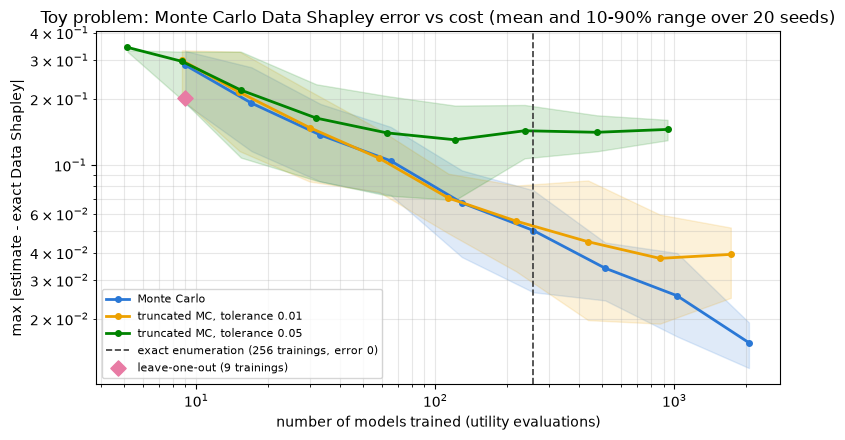

In [ ]:
BUDGETS = [1, 2, 4, 8, 16, 32, 64, 128, 256]
N_SEEDS = 20
toy_lookup = lambda S: toy_table[S]

estimators = {
    "Monte Carlo": lambda u, M, seed: mc_data_shapley(u, 8, M, seed),
    "truncated MC, tolerance 0.01": lambda u, M, seed: tmc_data_shapley(u, 8, M, 0.01, seed),
    "truncated MC, tolerance 0.05": lambda u, M, seed: tmc_data_shapley(u, 8, M, 0.05, seed),
}
mc_curves, mc_rows = {}, []
for name, estimator in estimators.items():
    calls, errors = np.zeros((len(BUDGETS), N_SEEDS)), np.zeros((len(BUDGETS), N_SEEDS))
    for b, budget in enumerate(BUDGETS):
        for seed in range(N_SEEDS):
            counted = CountingUtility(toy_lookup)
            estimate = estimator(counted, budget, seed)
            calls[b, seed], errors[b, seed] = counted.calls, (estimate - toy_exact).abs().max()
        mc_rows.append({"estimator": name, "orderings": budget, "mean trainings": calls[b].mean(), "mean max error": errors[b].mean()})
    mc_curves[name] = (calls.mean(1), errors.mean(1), np.quantile(errors, 0.1, axis=1), np.quantile(errors, 0.9, axis=1))

loo_error = (toy_loo - toy_exact).abs().max().item()
utils.plot_mc_convergence(
    mc_curves, exact_cost=256, loo_point=(9, loo_error),
    title="Toy problem: Monte Carlo Data Shapley error vs cost (mean and 10-90% range over 20 seeds)",
)
mc_table = pd.DataFrame(mc_rows).pivot(index="orderings", columns="estimator", values=["mean trainings", "mean max error"])
display(mc_table.loc[[4, 16, 32, 64, 256]].round(3))

<details>
<summary>Help - how should I interpret this plot?</summary>

**Monte Carlo (blue)** behaves like a textbook Monte Carlo estimator: on the log-log plot it's a straight line with slope about $-\tfrac{1}{2}$. Its worst-case error is 0.137 with 4 orderings (33 trainings), 0.067 with 16, 0.034 with 64 and 0.016 with 256 (2,049 trainings): each 4× increase in compute halves the error.

**Exact enumeration (dashed line)** costs 256 trainings and has zero error. At the same cost (32 orderings, 257 trainings), Monte Carlo still has a worst-case error of 0.050, and needs about 8 times more trainings to get to 0.016. On 8 points, enumerating is simply the better deal.

**Leave-one-out (diamond)** costs only 9 trainings, and its distance from Data Shapley (0.20) is smaller than Monte Carlo's with the same budget (one ordering, about 0.28). But unlike Monte Carlo, it can't be improved with more compute: it's an exact answer to a different question.

**Truncation** saves trainings, but less than you might hope on this problem, and at a price. With tolerance 0.01, 256 orderings use 1,721 trainings instead of 2,049 (16% fewer), but the error levels off at about 0.04 instead of continuing to fall. With tolerance 0.05, the saving is 54%, but the error is stuck at about 0.14 from 16 orderings onwards. That floor is the truncation bias: more orderings average away noise, not bias.
</details>

<details>
<summary>Question - why does truncation help so little on this problem, when it saves a lot on real datasets?</summary>

Truncation only saves trainings when coalitions get close to $v(D)$ well before the end of the ordering. With 8 examples, a typical prefix of 4 or 5 examples is still far from the full dataset (and until the mislabelled point arrives, a coalition's utility can be *higher* than $v(D)$: removing point 6 raises the utility from 0.508 to 0.635, and being above $v(D)$ by more than the tolerance doesn't trigger truncation either). On a dataset with thousands of examples, the learning curve flattens long before the end of the ordering, so most of each ordering can be skipped. We'll measure exactly how much truncation would save on our 128 digits in section 5️⃣.
</details>

## The scaling problem

On 8 points, Monte Carlo is actually a *worse* deal than exact enumeration: 256 trainings buys you the exact answer one way, and an answer with a worst-case error of about 0.05 (32 orderings) the other. Monte Carlo only pays off when $2^n$ is astronomically larger than the number of trainings you can afford, which is to say, on any real dataset.

But "affordable" is relative. Each ordering costs $n$ trainings. For our 128 digits, the 200 orderings we'll use in section 5️⃣ mean 25,600 trainings of a small network, per training seed. That's possible only because the network is tiny and each training takes milliseconds. For a dataset of $10^6$ examples, a single ordering is $10^6$ trainings; for a language model's pretraining set, even *one* retraining is a major expense. Retraining-based Data Shapley simply doesn't exist at that scale.

There's also a conceptual issue, pointed out by Wang et al. Retraining-based Data Shapley values a training example's contribution to a *learning algorithm*: it's the same for every model the algorithm could produce, and with a stochastic algorithm (random init, random minibatches) it's really an average over many possible training runs. Often, though, we care about one specific model, the one we trained and deployed. Which examples made *that* model good or bad?

Both problems are solved by changing the question. That's In-Run Data Shapley, and to build it we first need an efficient way of computing dot products between per-example gradients.

## Summary of 2️⃣

- Monte Carlo Data Shapley samples orderings of the data, and averages each example's marginal contribution when it arrives. It's unbiased, and its error falls like $1/\sqrt{\text{trainings}}$.
- Truncated Monte Carlo skips the end of each ordering once the coalition's utility is close to the full dataset's. It saves trainings at the cost of a bias that doesn't average away.
- Either way, the cost is measured in *models trained*, and it scales with the dataset size. That rules out retraining-based Data Shapley for large models, and it answers a question about a learning algorithm rather than about one trained model.

# 3️⃣ Per-Example Gradients and Ghost Dot Products

> ##### Learning Objectives
>
> - Express each layer's per-example weight gradient as an outer product of the layer's input and its output gradient
> - Implement the ghost dot product $\langle a_i^\top d_i, a_j^\top d_j \rangle = (a_i \cdot a_j)(d_i \cdot d_j)$, including bias terms, and check it against autograd
> - Measure how its cost scales with model size compared with materialising gradients

## The digits

From now on we'll work with a real (if small) dataset: the 8×8 handwritten digits that ship with scikit-learn (a copy of the UCI optical digits test set). We keep only 1s and 7s, and make three disjoint splits:

- **train**: 128 images (64 of each digit), which we'll value;
- **validation**: 48 images (24 of each), which define the utility, i.e. what "helpful" means;
- **test**: 64 images (32 of each), which we only ever use to evaluate the effect of deleting data. No attribution score is computed from the test set.

Then we flip the labels of 12 training images, 6 of each class. These are our planted "bad" examples. Real label noise is messier than this (it's often concentrated on genuinely ambiguous images), but planting it gives us something we can check every method against.

The data loading is in `utils.load_digit_splits`; the label flipping is below so you can see exactly what we did.

In [ ]:
splits = utils.load_digit_splits(seed=0)
train_x, clean_train_y = splits["train"]["x"], splits["train"]["y"]
val_x, val_y = splits["val"]["x"], splits["val"]["y"]
test_x, test_y = splits["test"]["x"], splits["test"]["y"]
N_TRAIN = len(train_x)

# Flip 6 labels of each class, chosen at random
flip_gen = t.Generator().manual_seed(0)
flipped = t.zeros(N_TRAIN, dtype=t.bool)
for label in [0.0, 1.0]:
    candidates = (clean_train_y == label).nonzero().flatten()
    flipped[candidates[t.randperm(len(candidates), generator=flip_gen)[:6]]] = True
train_y = t.where(flipped, 1 - clean_train_y, clean_train_y)

print(f"train {tuple(train_x.shape)}, val {tuple(val_x.shape)}, test {tuple(test_x.shape)}")
print(f"flipped training labels: {flipped.nonzero().flatten().tolist()}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">train (128, 64), val (48, 64), test (64, 64)
flipped training labels: [3, 17, 21, 44, 46, 47, 72, 80, 87, 89, 114, 120]</pre>

</details>

Here are the 12 flipped images next to 12 randomly chosen clean ones. The title is the label the model will be trained on; the red border marks a flipped label.


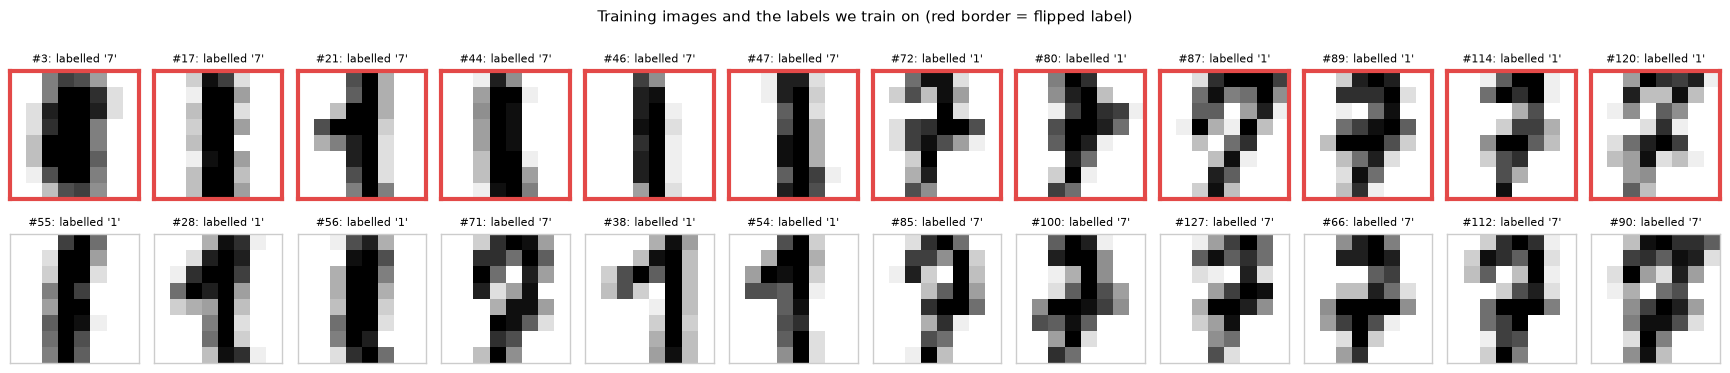

In [ ]:
shown = t.cat([flipped.nonzero().flatten(), (~flipped).nonzero().flatten()[t.randperm(116, generator=t.Generator().manual_seed(1))[:12]]])
utils.plot_digit_gallery(
    splits["train"]["images"][shown],
    [f"#{i}: labelled '{1 + 6 * int(train_y[i])}'" for i in shown.tolist()],
    flipped[shown].tolist(),
    "Training images and the labels we train on (red border = flipped label)",
    ncols=12,
)

## A network whose backward pass we can see

Our model is a multilayer perceptron with tanh hidden layers and a single output logit. We store the parameters as a plain list of `(W, b)` pairs, one per layer, with `W` of shape `(d_in, d_out)`, so a layer computes `h @ W + b`. For the digits we'll use one hidden layer of width 16, i.e. $64 \to 16 \to 1$, which has $64 \cdot 16 + 16 + 16 + 1 = 1073$ parameters. A network with *no* hidden layers, `[(W, b)]`, is just logistic regression, which we'll use to rerun the toy problem in section 4️⃣.

We'll write the forward and backward passes ourselves, without autograd. That's not because autograd can't compute per-example gradients (`torch.func.vmap` + `torch.func.grad` can). It's because we want to see *what a per-example gradient is made of*, and that structure is exactly what the ghost dot product exploits.

Notation: layer $k$ (counting from 0) takes input $a_k$ (so $a_0 = x$), and computes the pre-activation $s_k = a_k W_k + b_k$. For hidden layers the next input is $a_{k+1} = \tanh(s_k)$; the last layer's $s_{L-1}$ is the logit. For a single example with label $y$, the loss is $\ell = \text{BCE}(s_{L-1}, y)$.

In [ ]:
def init_mlp(sizes: list[int], seed: int) -> Params:
    """Gaussian init with variance 1/d_in for the weights, zeros for the biases."""
    gen = t.Generator().manual_seed(seed)
    return [
        (t.randn(d_in, d_out, generator=gen) / math.sqrt(d_in), t.zeros(d_out)) for d_in, d_out in zip(sizes[:-1], sizes[1:])
    ]

### Exercise - forward pass

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Implement `mlp_forward`, which returns the logits (shape `(batch,)`) and the list of every layer's **input** $[a_0, a_1, \dots, a_{L-1}]$ (each of shape `(batch, d_in)` for that layer). We'll need the layer inputs for the backward pass. Apply tanh after every layer except the last.

In [ ]:
def mlp_forward(params: Params, x: Float[Tensor, "batch d_in"]) -> tuple[Float[Tensor, " batch"], list[Tensor]]:
    """Returns (logits, layer_inputs), where layer_inputs[k] is the input to layer k."""
    raise NotImplementedError()


tests.test_mlp_forward(mlp_forward, init_mlp)

<details><summary>Solution</summary>

```python
def mlp_forward(params: Params, x: Float[Tensor, "batch d_in"]) -> tuple[Float[Tensor, " batch"], list[Tensor]]:
    """Returns (logits, layer_inputs), where layer_inputs[k] is the input to layer k."""
    layer_inputs = []
    h = x
    for k, (W, b) in enumerate(params):
        layer_inputs.append(h)
        h = h @ W + b
        if k < len(params) - 1:
            h = t.tanh(h)
    return h.squeeze(-1), layer_inputs
```
</details>

We'll also need the (mean) loss in many places:

In [ ]:
def mlp_loss(params: Params, x: Float[Tensor, "batch d_in"], y: Float[Tensor, " batch"]) -> Float[Tensor, ""]:
    """Mean binary cross-entropy of the MLP on (x, y)."""
    return F.binary_cross_entropy_with_logits(mlp_forward(params, x)[0], y)

## Per-example gradients are outer products

Write $d_k = \partial \ell / \partial s_k$ for the gradient of one example's loss with respect to layer $k$'s pre-activation (we'll call it the layer's **output gradient**). Two facts give us everything:

**1. The output gradients come from the usual backward recursion.** For the final layer, the derivative of the binary cross-entropy with respect to the logit is simply

$$
d_{L-1} = \sigma(s_{L-1}) - y,
$$

and for each earlier layer, the chain rule through $s_{k+1} = \tanh(s_k) W_{k+1} + b_{k+1}$ gives

$$
d_k = \big(d_{k+1} W_{k+1}^\top\big) \odot \big(1 - a_{k+1}^2\big),
$$

using $\tanh'(s_k) = 1 - \tanh(s_k)^2 = 1 - a_{k+1}^2$.

**2. Each layer's per-example parameter gradient is built from its input and its output gradient.** Since $s_k = a_k W_k + b_k$,

$$
\frac{\partial \ell}{\partial W_k} = a_k^\top d_k \quad \text{(an outer product, shape } d_{in} \times d_{out}\text{)}, \qquad \frac{\partial \ell}{\partial b_k} = d_k.
$$

(Throughout, we treat $a_k$ and $d_k$ as *row* vectors, as they are in the code, so $a_k^\top d_k$ is a column times a row: a matrix.)

So for a batch of $B$ examples, the pair $(A_k, D_k)$ of shapes `(B, d_in)` and `(B, d_out)` is a compressed representation of all $B$ per-example gradients of layer $k$. We'll call these pairs the **factors** of the gradient. Ordinary backprop computes exactly these factors and then immediately sums over the batch ($A_k^\top D_k$) to get the batch gradient. We're going to stop just before that sum.

### Exercise - backpropagate the factors

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 15-20 minutes on this exercise.
> ```

Implement `backprop_factors`, which returns a list with one `(a_k, d_k)` pair per layer (in forward order), for the **unreduced** per-example losses: don't divide by the batch size anywhere. `a_k` is layer $k$'s input, shape `(batch, d_in)`, and `d_k` is its output gradient, shape `(batch, d_out)`; for the last layer `d_out = 1`, so remember to add a trailing dimension.

There's no test cell directly below this one: the easiest way to check the factors is to turn them into full gradients and compare against autograd, which is the next exercise.

In [ ]:
def backprop_factors(params: Params, x: Float[Tensor, "batch d_in"], y: Float[Tensor, " batch"]) -> list[tuple[Tensor, Tensor]]:
    """
    Returns [(a_0, d_0), ..., (a_{L-1}, d_{L-1})]: each layer's input and the gradient of each example's own
    (unreduced) BCE loss with respect to that layer's pre-activation.
    """
    raise NotImplementedError()

<details>
<summary>Hint</summary>

Start from `d = (t.sigmoid(logits) - y)[:, None]` and loop over layers backwards. At layer `k`, record `(layer_inputs[k], d)`, then (if `k > 0`) propagate: `d = (d @ W_k.T) * (1 - layer_inputs[k] ** 2)`. Note that `layer_inputs[k]` is $a_k = \tanh(s_{k-1})$, so it's the right thing to use for the tanh derivative of layer $k - 1$. Reverse the list at the end.
</details>


<details><summary>Solution</summary>

```python
def backprop_factors(params: Params, x: Float[Tensor, "batch d_in"], y: Float[Tensor, " batch"]) -> list[tuple[Tensor, Tensor]]:
    """
    Returns [(a_0, d_0), ..., (a_{L-1}, d_{L-1})]: each layer's input and the gradient of each example's own
    (unreduced) BCE loss with respect to that layer's pre-activation.
    """
    logits, layer_inputs = mlp_forward(params, x)
    d = (t.sigmoid(logits) - y)[:, None]
    factors = []
    for k in reversed(range(len(params))):
        factors.append((layer_inputs[k], d))
        if k > 0:
            d = (d @ params[k][0].T) * (1 - layer_inputs[k] ** 2)
    return factors[::-1]
```
</details>

### Exercise - materialise per-example gradients

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

To check the factors (and to have a slow reference implementation to compare against), implement `per_example_grads`, which turns the factors into explicit per-example gradient vectors, shape `(batch, n_params)`. Use this parameter order: for each layer in turn, the weight gradient flattened in `(d_in, d_out)` row-major order, then the bias gradient. (That's the order you get from `t.cat([W.flatten(), b] for each layer)`.)

The test compares your result, built from your `backprop_factors`, against per-example gradients from autograd.

In [ ]:
def per_example_grads(factors: list[tuple[Tensor, Tensor]]) -> Float[Tensor, "batch n_params"]:
    """Materialises every example's full gradient vector from the factors."""
    raise NotImplementedError()


tests.test_backprop_factors(backprop_factors, per_example_grads, mlp_forward, init_mlp)

<details>
<summary>Hint</summary>

For one layer, `a[:, :, None] * d[:, None, :]` has shape `(batch, d_in, d_out)` and contains every example's outer product. Flatten the last two dimensions, then concatenate it and `d` (the bias gradient) for every layer along dimension 1.
</details>


<details><summary>Solution</summary>

```python
def per_example_grads(factors: list[tuple[Tensor, Tensor]]) -> Float[Tensor, "batch n_params"]:
    """Materialises every example's full gradient vector from the factors."""
    blocks = []
    for a, d in factors:
        blocks.append((a[:, :, None] * d[:, None, :]).flatten(1))  # per-example outer products a_i^T d_i
        blocks.append(d)
    return t.cat(blocks, dim=1)
```
</details>

## The ghost dot product

In-Run Data Shapley needs, at every training step, the dot product between each training example's gradient and the validation gradient. Materialising the per-example gradients costs $O(B \cdot P)$ memory for a batch of $B$ examples and a model with $P$ parameters. For a language model with $P = 10^9$ that's out of the question.

But look at the dot product of two per-example weight gradients of the same layer. Since they're both outer products,

$$
\big\langle a_i^\top d_i,\; a_j^\top d_j \big\rangle_F = \sum_{p, q} a_{ip}\, d_{iq}\, a_{jp}\, d_{jq} = \Big(\sum_p a_{ip} a_{jp}\Big)\Big(\sum_q d_{iq} d_{jq}\Big) = (a_i \cdot a_j)(d_i \cdot d_j).
$$

The dot product of two $d_{in} \times d_{out}$ matrices has become the product of two dot products, of length $d_{in}$ and $d_{out}$. The bias gradients add $d_i \cdot d_j$, and different layers own different parameters, so the full gradient dot product is a sum over layers:

$$
g_i \cdot g_j = \sum_{k} \big(a_{k,i} \cdot a_{k,j} + 1\big)\big(d_{k,i} \cdot d_{k,j}\big).
$$

For two batches at once, this is a pair of Gram matrices per layer and an elementwise product: $(A_k A_k'^\top + 1) \odot (D_k D_k'^\top)$. This is the **ghost dot product** (the name comes from "ghost clipping" in differentially private training, which uses the same trick to compute per-example gradient *norms*; see Li et al. in the further reading). In-Run Data Shapley applies it with the validation examples appended to the training batch, so that one backward pass over `[training batch; validation batch]` produces every factor needed for all the train-validation dot products, at roughly the cost of an ordinary training step.

<details>
<summary>Aside - when does this identity break?</summary>

The derivation assumed that each example's gradient for a layer is a *single* outer product $a_i^\top d_i$. That's true for an MLP on vector inputs. It's not true in general:

- **Sequence models.** In a transformer, a linear layer is applied at every token position, so an example's weight gradient is a *sum* of outer products, $\sum_{t} a_{it}^\top d_{it}$. The dot product becomes $\sum_{t, t'} (a_{it} \cdot a_{jt'})(d_{it} \cdot d_{jt'})$, which costs $O(T^2)$ per pair; the paper discusses when this is cheaper than materialising the gradient.
- **Tied or shared parameters** (e.g. tied embedding and unembedding) get gradient contributions from several places, which all need to be included.
- **Batch-dependent layers** like batch norm couple examples, so "the gradient of example $i$" isn't even well-defined without extra choices.
</details>

### Exercise - implement the ghost dot product

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `ghost_dot_products`, which takes the factors of two batches (of sizes $B_1$ and $B_2$, for the same network) and returns the `(B_1, B_2)` matrix of per-example gradient dot products. No tensor in your implementation should have a dimension of size `n_params`.

In [ ]:
def ghost_dot_products(
    factors_1: list[tuple[Tensor, Tensor]], factors_2: list[tuple[Tensor, Tensor]]
) -> Float[Tensor, "batch_1 batch_2"]:
    """Returns the matrix of dot products g_i . g_j between per-example gradients, without materialising them."""
    raise NotImplementedError()


tests.test_ghost_dot_products(ghost_dot_products, backprop_factors, init_mlp)

<details>
<summary>Hint</summary>

For each layer, `a_1 @ a_2.T` is the `(B_1, B_2)` Gram matrix of inputs and `d_1 @ d_2.T` the Gram matrix of output gradients. Add 1 to the first (for the bias), multiply elementwise, and sum over layers.
</details>


<details><summary>Solution</summary>

```python
def ghost_dot_products(
    factors_1: list[tuple[Tensor, Tensor]], factors_2: list[tuple[Tensor, Tensor]]
) -> Float[Tensor, "batch_1 batch_2"]:
    """Returns the matrix of dot products g_i . g_j between per-example gradients, without materialising them."""
    total = 0.0
    for (a_1, d_1), (a_2, d_2) in zip(factors_1, factors_2):
        total = total + (a_1 @ a_2.T + 1) * (d_1 @ d_2.T)
    return total
```
</details>

### Exercise - SGD with a fixed denominator

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

The factors also give us the batch gradient, so we can train with them. Implement:

- `sgd_step`, which returns the parameters after one SGD step, $W_k \leftarrow W_k - \frac{\eta}{\text{denominator}} \sum_i w_i\, a_{k,i}^\top d_{k,i}$ and $b_k \leftarrow b_k - \frac{\eta}{\text{denominator}} \sum_i w_i\, d_{k,i}$. The optional per-example `weights` $w_i$ (default: all ones) let us switch examples off. As in section 1️⃣, the denominator stays fixed when examples are switched off.
- `sgd_train`, which runs `sgd_step` over a **schedule**: a list of index tensors, one minibatch per step, using `len(batch)` as the denominator. The optional `keep` (shape `(n,)`, 0/1) switches examples off for the whole run: this is how we'll "retrain without" a set of examples, with the same initialisation and the same minibatches.

Don't modify `params` in place: return new tensors.

In [ ]:
def sgd_step(
    params: Params, factors: list[tuple[Tensor, Tensor]], lr: float, denominator: int, weights: Tensor | None = None
) -> Params:
    """One SGD step on sum_i weights_i * loss_i / denominator, computed from the gradient factors."""
    raise NotImplementedError()


def sgd_train(
    params: Params, x: Tensor, y: Tensor, schedule: list[Tensor], lr: float, keep: Tensor | None = None
) -> Params:
    """Runs SGD over the minibatch schedule. Examples with keep[i] == 0 never contribute to an update."""
    raise NotImplementedError()


tests.test_sgd_step(sgd_step, backprop_factors, init_mlp)
tests.test_sgd_train(sgd_train, init_mlp)

<details>
<summary>Hint</summary>

The batch gradient of layer $k$ is $\sum_i a_{k,i}^\top d_{k,i} = A_k^\top D_k$, i.e. `a.T @ d`. Multiply `d` by `weights[:, None]` first if weights are given.
</details>


<details><summary>Solution</summary>

```python
def sgd_step(
    params: Params, factors: list[tuple[Tensor, Tensor]], lr: float, denominator: int, weights: Tensor | None = None
) -> Params:
    """One SGD step on sum_i weights_i * loss_i / denominator, computed from the gradient factors."""
    new_params = []
    for (W, b), (a, d) in zip(params, factors):
        if weights is not None:
            d = d * weights[:, None]
        new_params.append((W - lr * a.T @ d / denominator, b - lr * d.sum(0) / denominator))
    return new_params


def sgd_train(
    params: Params, x: Tensor, y: Tensor, schedule: list[Tensor], lr: float, keep: Tensor | None = None
) -> Params:
    """Runs SGD over the minibatch schedule. Examples with keep[i] == 0 never contribute to an update."""
    for batch in schedule:
        factors = backprop_factors(params, x[batch], y[batch])
        params = sgd_step(params, factors, lr, len(batch), None if keep is None else keep[batch])
    return params
```
</details>

## Training on the digits

Our training recipe for the digits: the $64 \to 16 \to 1$ MLP, plain SGD with learning rate 0.1, minibatches of 4, and 4 epochs over the 128 training images, for $T = 128$ steps in total. The **schedule** (which images are in which minibatch, in which order) is fixed by a seed, as is the initialisation. We'll use three seeds, 0, 1 and 2, for every experiment on the digits, and report all three.

Let's train the seed-0 model, and compare it against the same run with the flipped images switched off. This is the experiment from the introduction.

In [ ]:
SIZES = [64, 16, 1]
LR, BATCH_SIZE, EPOCHS = 0.1, 4, 4
SEEDS = [0, 1, 2]


def make_schedule(n: int, batch_size: int, epochs: int, seed: int) -> list[Int[Tensor, " batch"]]:
    """A fixed list of minibatches: each epoch is a fresh random permutation of range(n), cut into batches."""
    gen = t.Generator().manual_seed(seed)
    return [batch for _ in range(epochs) for batch in t.randperm(n, generator=gen).reshape(-1, batch_size)]


@t.no_grad()
def evaluate(params: Params, x: Tensor, y: Tensor) -> tuple[float, float]:
    """Returns (mean BCE loss, accuracy)."""
    logits = mlp_forward(params, x)[0]
    return F.binary_cross_entropy_with_logits(logits, y).item(), ((logits > 0).double() == y).double().mean().item()

In [ ]:
params0 = init_mlp(SIZES, seed=0)
schedule0 = make_schedule(N_TRAIN, BATCH_SIZE, EPOCHS, seed=0)
trained = sgd_train(params0, train_x, train_y, schedule0, LR)
trained_without_flips = sgd_train(params0, train_x, train_y, schedule0, LR, keep=(~flipped).double())

for name, p in [("all 128 images", trained), ("flipped images switched off", trained_without_flips)]:
    (val_loss, val_acc), (test_loss, test_acc) = evaluate(p, val_x, val_y), evaluate(p, test_x, test_y)
    print(f"{name:<28}  val loss {val_loss:.4f} (acc {val_acc:.1%})   test loss {test_loss:.4f} (acc {test_acc:.1%})")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">all 128 images                val loss 0.1259 (acc 100.0%)   test loss 0.1493 (acc 98.4%)
flipped images switched off   val loss 0.0420 (acc 100.0%)   test loss 0.0571 (acc 100.0%)</pre>

</details>

1s versus 7s is an easy task: both models classify every validation image correctly, and the model trained on all 128 images gets only one of the 64 test images wrong. The 12 flipped labels show up mostly in the *loss*: the model trained on them is less confident on clean data, because it has been told that some perfectly normal-looking 1s are 7s. Throughout the rest of the notebook, "helpful" means "reduces validation loss", and the test loss is what we'll use to check whether deleting data really helped.

## What are the training examples saying to the validation set?

Before building anything on top of the ghost dot product, let's look at what it computes. The entry $g_i \cdot g_j$ for training image $i$ and validation image $j$ has a direct meaning: an SGD step on example $i$ alone changes the loss on $j$ by approximately $-\eta\, g_i \cdot g_j$. So a **positive** dot product means training on $i$ *reduces* the loss on $j$ (they "agree"), and a negative one means it increases it.

The cell below computes the full $128 \times 48$ matrix at initialisation and at the end of training, with the training images sorted by digit and by whether their label was flipped, and the validation images sorted by digit.


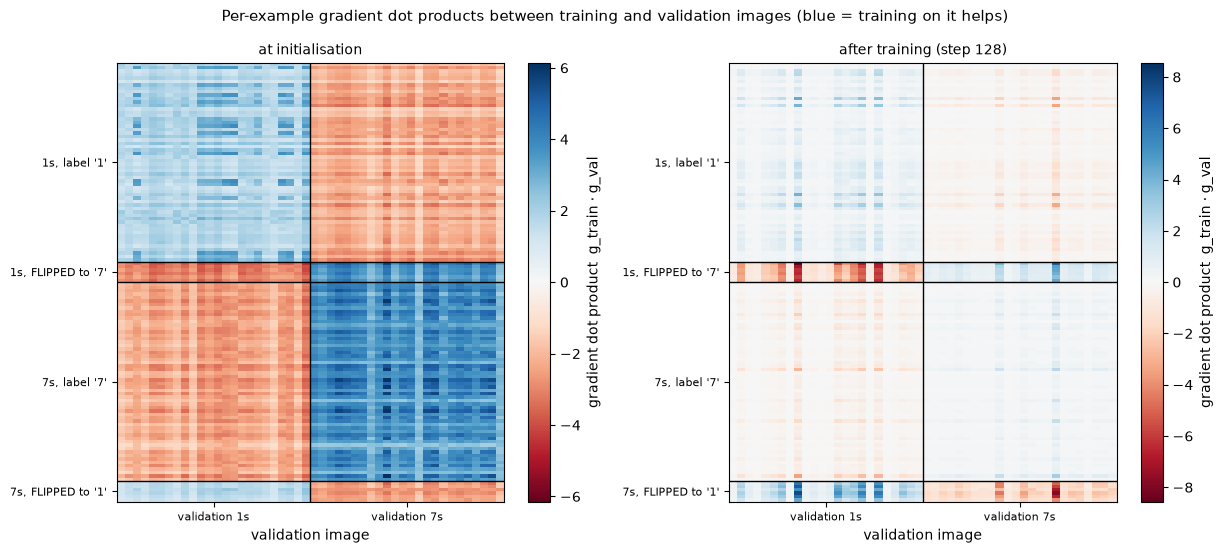

In [ ]:
train_digit = splits["train"]["digit"]
row_order = sorted(range(N_TRAIN), key=lambda i: (train_digit[i].item(), flipped[i].item()))
col_order = val_y.argsort(stable=True)
group_sizes = [((train_digit == d) & (flipped == f)).sum().item() for d in [1, 7] for f in [False, True]]
row_boundaries = np.cumsum(group_sizes)[:-1].tolist()

similarity = {}
for name, p in [("at initialisation", params0), ("after training (step 128)", trained)]:
    sims = ghost_dot_products(backprop_factors(p, train_x, train_y), backprop_factors(p, val_x, val_y))
    similarity[name] = sims[row_order][:, col_order]

utils.plot_similarity_heatmaps(
    similarity,
    row_boundaries=row_boundaries,
    row_names=["1s, label '1'", "1s, FLIPPED to '7'", "7s, label '7'", "7s, FLIPPED to '1'"],
    col_boundaries=[24],
    col_names=["validation 1s", "validation 7s"],
    suptitle="Per-example gradient dot products between training and validation images (blue = training on it helps)",
)
for name, sims in similarity.items():
    rows = sims.mean(1)
    is_flipped = flipped[row_order]
    print(f"{name:<26} mean row: clean {rows[~is_flipped].mean():+.3f}, flipped {rows[is_flipped].mean():+.3f}")

<details>
<summary>Help - how should I interpret these heatmaps?</summary>

**At initialisation**, the pattern is a checkerboard by *label*, not by digit. Every training image labelled '7', including the six 1s that were flipped to '7', has positive dot products with the validation 7s and negative ones with the validation 1s, and vice versa. A random network barely distinguishes 1s from 7s, so a training step mostly says "push the logit up" or "push it down", and the label decides which. The *size* of each entry still depends on the images, through the $a_i \cdot a_j$ factor, which is larger for similar-looking images. A 1 labelled '7' pushes in the direction that helps the validation 7s, but it *looks like* the validation 1s, so its (negative) dot products with the 1s it hurts tend to be larger than its (positive) ones with the 7s it helps. On average over the validation set, clean rows are positive (+0.280) and flipped rows slightly negative (-0.083).

**After training**, almost everything has faded. The model fits the clean training images, so their output gradients $\sigma(s) - y$ are tiny, and so are their dot products with anything (mean +0.046). The rows that stay bright are the flipped ones (mean -0.269). A 1 labelled '7' now has a strongly negative dot product with the validation 1s (a step on it would make the model worse on real 1s) and a weaker positive one with the validation 7s. A few validation columns are brighter than the rest: these are the validation images with the highest loss, whose own output gradients are therefore the largest.

This matrix, evaluated at every training step, is the raw material of In-Run Data Shapley. Each step credits the examples in the minibatch with their row of this matrix, averaged over the validation columns and scaled by the learning rate.
</details>

## What does the ghost trick buy?

On our 1073-parameter network, materialising per-example gradients is cheap. The point of the ghost dot product is how the two approaches *scale*. The cell below times both ways of computing a $32 \times 48$ matrix of train-validation dot products, for networks of increasing width, and checks that they agree. (Timings depend on your machine and on what else it's doing; we take the best of 5 runs.)


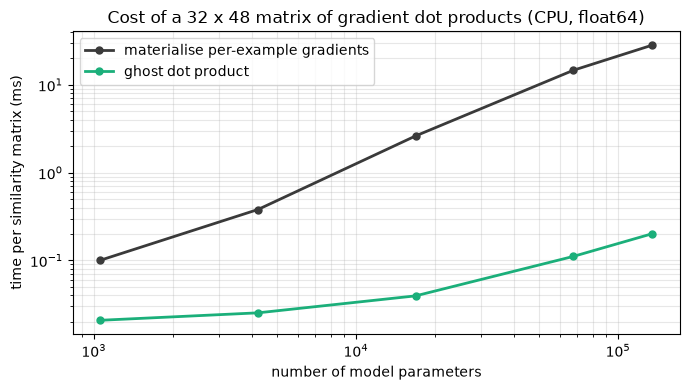

In [ ]:
timing_params, timing = [], {"materialise per-example gradients": [], "ghost dot product": []}
for width in [16, 64, 256, 1024, 2048]:
    p = init_mlp([64, width, 1], seed=0)
    factors_train, factors_val = backprop_factors(p, train_x[:32], train_y[:32]), backprop_factors(p, val_x, val_y)
    timing_params.append(sum(W.numel() + b.numel() for W, b in p))
    for name, fn in [
        ("materialise per-example gradients", lambda: per_example_grads(factors_train) @ per_example_grads(factors_val).T),
        ("ghost dot product", lambda: ghost_dot_products(factors_train, factors_val)),
    ]:
        times = []
        for _ in range(5):
            start = time.perf_counter()
            result = fn()
            times.append(time.perf_counter() - start)
        timing[name].append(min(times))
    t.testing.assert_close(per_example_grads(factors_train) @ per_example_grads(factors_val).T, ghost_dot_products(factors_train, factors_val))

utils.plot_timing(timing_params, timing, "Cost of a 32 x 48 matrix of gradient dot products (CPU, float64)")
for n_p, slow, fast in zip(timing_params, *timing.values()):
    print(f"{n_p:>8} params: materialised {slow * 1e3:7.2f} ms, ghost {fast * 1e3:6.3f} ms  ({slow / fast:5.0f}x)")

<details>
<summary>Help - how should I interpret this plot?</summary>

At the size of our digits model (about 1,000 parameters) the two approaches differ by a factor of about 5, and both take a fraction of a millisecond. As the hidden layer widens, the cost of materialising grows in proportion to the number of parameters (it builds an $80 \times P$ matrix), while the ghost dot product only needs Gram matrices of size $32 \times 48$ over vectors of length $d_{in}$ and $d_{out}$. At 135,000 parameters the ghost version is about 130 times faster, and both give the same numbers (the cell asserts this).

The bigger difference for real models is memory. Materialising per-example gradients for 80 examples of a 1-billion-parameter model would take 320 GB in float32. The ghost dot product never stores anything larger than the activations and output gradients that backprop computes anyway.
</details>

## Summary of 3️⃣

- In an MLP, an example's gradient for a linear layer is the outer product of the layer's input and the gradient at the layer's output. Backprop computes these **factors** for every example anyway, and then sums them.
- The dot product of two such gradients factorises: $(a_i \cdot a_j + 1)(d_i \cdot d_j)$ per layer. This **ghost dot product** gives exactly the same numbers as materialising the gradients, at a cost that depends on the layer *widths* rather than on the number of parameters.
- The train-validation dot products are already informative on their own: at the end of training, the images that push against the validation set are, overwhelmingly, the ones with flipped labels.

Next, we'll turn these dot products into a credit allocation for a whole training run.

# 4️⃣ In-Run Data Shapley

> ##### Learning Objectives
>
> - Understand how In-Run Data Shapley decomposes a training run into per-step cooperative games, and why the per-step values telescope
> - Implement first-order and second-order In-Run Data Shapley using ghost dot products and a Hessian-vector product
> - Measure how far the first-order approximation is from the exact per-step values, and when it matters

## One game per training step

Here is the key idea of Wang et al. ([*Data Shapley in One Training Run*](https://arxiv.org/abs/2406.11011), ICLR 2025). Instead of asking how each example contributes to the outcome of the learning *algorithm*, ask how it contributes to one particular training *run*, and break that run into its steps.

At step $t$, SGD is at parameters $\theta_t$, and updates using the minibatch $\mathcal{B}_t$ of size $B$:

$$
\theta_{t+1} = \theta_t - \frac{\eta}{B} \sum_{i \in \mathcal{B}_t} g_{t,i}, \qquad g_{t,i} = \nabla_\theta\, \ell(\theta_t; z_i).
$$

The examples in the minibatch are the only ones that affect this step, so define a small cooperative game whose players are the $B$ examples in $\mathcal{B}_t$. For a coalition $S \subseteq \mathcal{B}_t$, the **local utility** is the validation loss improvement we'd get from applying only $S$'s part of the update, starting from the *same* checkpoint $\theta_t$ and keeping the same denominator:

$$
U_t(S) = L_{val}(\theta_t) - L_{val}\Big(\theta_t - \frac{\eta}{B}\sum_{i \in S} g_{t,i}\Big).
$$

For the full minibatch, $U_t(\mathcal{B}_t) = L_{val}(\theta_t) - L_{val}(\theta_{t+1})$ is exactly the improvement that step actually made. So summing over steps **telescopes**:

$$
\sum_{t=0}^{T-1} U_t(\mathcal{B}_t) = L_{val}(\theta_0) - L_{val}(\theta_T).
$$

The **In-Run Data Shapley** value of example $i$ is the sum of its Shapley values in all the local games it took part in (zero for steps where it wasn't in the minibatch):

$$
\phi_i^{\text{in-run}} = \sum_{t\,:\, i \in \mathcal{B}_t} \phi_i(U_t).
$$

Because each local game is efficient, the In-Run values of all examples add up to the actual improvement in validation loss over the whole run. This is what the paper calls a "contribution accountant": every bit of the improvement is credited to some example at some step.

Notice what this does and doesn't ask. Each local game starts from $\theta_t$, the checkpoint the *real* run reached with all the data. It never asks what would have happened later if example $i$ had been missing earlier (that would need retraining). In exchange, everything can be computed during the run, with no retraining at all. With minibatches of 4, each local game has only $2^4 = 16$ coalitions, so we can even compute it exactly. That's what we'll do first.

### Exercise - the local game at one step

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `local_game_values`. Given the current parameters, the factors of the current minibatch (from `backprop_factors`), the validation set, the learning rate and the denominator, return a tensor of the $2^B$ local utilities $U_t(S)$, indexed by **bitmask**: entry `m` is the utility of the coalition $\{i : \text{bit } i \text{ of } m \text{ is } 1\}$. So entry 0 is the empty coalition (utility 0) and entry $2^B - 1$ is the whole batch.

Use `sgd_step` with 0/1 `weights` to apply each coalition's part of the update. Every coalition starts from the same `params`.

In [ ]:
def local_game_values(
    params: Params, factors: list[tuple[Tensor, Tensor]], val_x: Tensor, val_y: Tensor, lr: float, denominator: int
) -> Float[Tensor, " two_to_the_B"]:
    """U_t(S) for every coalition S of the minibatch, indexed by bitmask."""
    raise NotImplementedError()


tests.test_local_game_values(local_game_values, backprop_factors, init_mlp)

<details>
<summary>Hint</summary>

For each `mask` in `range(2 ** B)`, the weights are `[(mask >> i) & 1 for i in range(B)]`. Compute `mlp_loss(params, val_x, val_y) - mlp_loss(sgd_step(params, factors, lr, denominator, weights), val_x, val_y)`.
</details>


<details><summary>Solution</summary>

```python
def local_game_values(
    params: Params, factors: list[tuple[Tensor, Tensor]], val_x: Tensor, val_y: Tensor, lr: float, denominator: int
) -> Float[Tensor, " two_to_the_B"]:
    """U_t(S) for every coalition S of the minibatch, indexed by bitmask."""
    batch_size = factors[0][0].shape[0]
    loss_before = mlp_loss(params, val_x, val_y)
    values = []
    for mask in range(2**batch_size):
        weights = t.tensor([float((mask >> i) & 1) for i in range(batch_size)])
        values.append(loss_before - mlp_loss(sgd_step(params, factors, lr, denominator, weights), val_x, val_y))
    return t.stack(values)
```
</details>

A local game is just another cooperative game, so we can reuse `exact_data_shapley` from section 1️⃣ to allocate it. We only need to turn the bitmask-indexed table into a function of `frozenset`s:

In [ ]:
def exact_local_shapley(values: Float[Tensor, " two_to_the_B"]) -> Float[Tensor, " B"]:
    """Exact Shapley values of a bitmask-indexed game, using exact_data_shapley from section 1."""
    batch_size = values.numel().bit_length() - 1
    shapley, _ = exact_data_shapley(lambda S: values[sum(1 << i for i in S)].item(), batch_size)
    return shapley

## The first-order approximation

Enumerating $2^B$ coalitions is fine for $B = 4$, but real minibatches have hundreds or thousands of examples. The paper's way out is a Taylor expansion of the local utility around $\theta_t$. Write $\alpha = \eta / B$ and $g_{val} = \nabla_\theta L_{val}(\theta_t)$. To first order,

$$
U_t(S) \approx L_{val}(\theta_t) - \Big(L_{val}(\theta_t) - \alpha\, g_{val} \cdot \sum_{i \in S} g_{t,i}\Big) = \sum_{i \in S} \alpha\, g_{val} \cdot g_{t,i}.
$$

This approximate game is **additive**: the utility of a coalition is a sum of one term per member, with no interactions. The Shapley value of an additive game is just each player's own term, so

$$
\phi^{(1)}_i(U_t) = \frac{\eta}{B}\, g_{t,i} \cdot g_{val}.
$$

That's the whole first-order method: the learning rate times the dot product between the example's gradient and the validation gradient, summed over the steps where the example appears. (If you've met TracIn, this should look familiar: TracIn is the same sum, evaluated at a handful of saved checkpoints rather than at every step. See [16.10].)

Our validation loss is the *mean* over 48 validation images, so $g_{val}$ is the mean of the 48 per-example validation gradients, and $g_{t,i} \cdot g_{val}$ is the mean of row $i$ of the ghost dot product matrix between the batch and the validation set.

### Exercise - first-order credit

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Implement `first_order_credit`, which takes the `(B, n_val)` matrix of dot products between the minibatch's and the validation examples' gradients, and returns the first-order credit of each minibatch example, shape `(B,)`.

In [ ]:
def first_order_credit(train_val_dots: Float[Tensor, "B n_val"], lr: float, denominator: int) -> Float[Tensor, " B"]:
    """First-order In-Run credit (lr / denominator) * g_i . g_val, where g_val is the mean validation gradient."""
    raise NotImplementedError()


tests.test_first_order_credit(first_order_credit)

<details><summary>Solution</summary>

```python
def first_order_credit(train_val_dots: Float[Tensor, "B n_val"], lr: float, denominator: int) -> Float[Tensor, " B"]:
    """First-order In-Run credit (lr / denominator) * g_i . g_val, where g_val is the mean validation gradient."""
    return lr / denominator * train_val_dots.mean(dim=1)
```
</details>

## The second-order approximation

The first-order game ignores two things: the curvature of the validation loss, and the fact that examples in the same minibatch *interact* (if two examples push in the same direction, the second push is worth less once the first has happened). Both show up at second order. With $H_{val} = \nabla^2_\theta L_{val}(\theta_t)$ and $\Delta_S = -\alpha \sum_{i \in S} g_{t,i}$,

$$
U_t(S) \approx -g_{val} \cdot \Delta_S - \tfrac{1}{2} \Delta_S^\top H_{val} \Delta_S = \alpha \sum_{i \in S} g_{val} \cdot g_{t,i} - \frac{\alpha^2}{2} \sum_{i \in S} \sum_{j \in S} g_{t,i}^\top H_{val}\, g_{t,j}.
$$

The double sum contains a *self* term $g_i^\top H g_i$ for every member, and a *pairwise* term $2\, g_i^\top H g_j$ for every unordered pair. The Shapley value of a self term goes entirely to its owner, and the Shapley value of a pairwise term (a game where the payoff only appears when both $i$ and $j$ are present) is split equally between the two. Adding these up,

$$
\phi^{(2)}_i(U_t) = \underbrace{\alpha\, g_{t,i} \cdot g_{val}}_{\text{first order}} \;-\; \frac{\alpha^2}{2}\, g_{t,i}^\top H_{val} \Big(\sum_{j \in \mathcal{B}_t} g_{t,j}\Big).
$$

The sum inside the brackets is the batch gradient (times $B$), so the correction needs one **Hessian-vector product** $H_{val} v$ per step, with $v = \sum_j g_{t,j}$, followed by the dot product of each example's gradient with the vector $H_{val} v$.

Computing a Hessian-vector product is a standard autograd operation ("double backward"), and it isn't what this section is about, so we've written it for you. It takes a vector in the same `Params` format as the parameters.

In [ ]:
def val_hvp(params: Params, val_x: Tensor, val_y: Tensor, vector: Params) -> Params:
    """Returns H_val @ vector, where H_val is the Hessian of the mean validation loss at `params`."""
    leaves = [p.detach().clone().requires_grad_(True) for pair in params for p in pair]
    pairs = [(leaves[2 * k], leaves[2 * k + 1]) for k in range(len(params))]
    grads = t.autograd.grad(mlp_loss(pairs, val_x, val_y), leaves, create_graph=True)
    grad_dot_vector = sum((g * v).sum() for g, v in zip(grads, [v for pair in vector for v in pair]))
    hvp = t.autograd.grad(grad_dot_vector, leaves)
    return [(hvp[2 * k].detach(), hvp[2 * k + 1].detach()) for k in range(len(params))]

The other ingredient, the dot product of every per-example gradient with a fixed parameter-shaped vector $u = (U_k, u_k)_k$, has its own ghost identity: for the weights,

$$
\langle a_i^\top d_i,\, U_k \rangle_F = \sum_{p,q} a_{ip}\, U_{k,pq}\, d_{iq} = a_i\, U_k\, d_i^\top,
$$

and the bias contributes $d_i \cdot u_k$. Again, no per-example gradient is ever formed.

### Exercise - ghost gradient-vector products

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Implement `ghost_vector_products`, which returns $g_i \cdot u$ for every example in the batch, shape `(B,)`.

In [ ]:
def ghost_vector_products(factors: list[tuple[Tensor, Tensor]], vector: Params) -> Float[Tensor, " B"]:
    """Returns g_i . vector for every example i, without materialising g_i."""
    raise NotImplementedError()


tests.test_ghost_vector_products(ghost_vector_products, backprop_factors, init_mlp)

<details>
<summary>Hint</summary>

`a @ U` has shape `(B, d_out)`; multiplying elementwise by `d` and summing over the last dimension gives $a_i U d_i^\top$ for every $i$.
</details>


<details><summary>Solution</summary>

```python
def ghost_vector_products(factors: list[tuple[Tensor, Tensor]], vector: Params) -> Float[Tensor, " B"]:
    """Returns g_i . vector for every example i, without materialising g_i."""
    total = 0.0
    for (a, d), (U, u) in zip(factors, vector):
        total = total + ((a @ U) * d).sum(dim=-1) + d @ u
    return total
```
</details>

### Exercise - second-order credit

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 15 minutes on this exercise.
> ```

Implement `second_order_credit`. Given the first-order credit for the batch (from `first_order_credit`), it should:

1. build the batch-gradient vector $v = \sum_{j \in \mathcal{B}_t} g_{t,j}$ in `Params` format from the factors (for each layer, `(a.T @ d, d.sum(0))`);
2. compute $H_{val} v$ with `val_hvp`;
3. return $\phi^{(1)}_i - \frac{1}{2}\left(\frac{\eta}{B}\right)^2 g_{t,i} \cdot (H_{val} v)$, using `ghost_vector_products`.

The test checks your function on a game where the second-order expansion is *exact* (a quadratic loss), against brute-force Shapley values.

In [ ]:
def second_order_credit(
    params: Params,
    factors: list[tuple[Tensor, Tensor]],
    val_x: Tensor,
    val_y: Tensor,
    lr: float,
    denominator: int,
    first_order: Float[Tensor, " B"],
    hvp_fn: Callable = val_hvp,
) -> Float[Tensor, " B"]:
    """Second-order In-Run credit: first order minus (lr/denominator)^2 / 2 * g_i^T H_val sum_j g_j."""
    raise NotImplementedError()


tests.test_second_order_credit(second_order_credit, ghost_vector_products)

<details><summary>Solution</summary>

```python
def second_order_credit(
    params: Params,
    factors: list[tuple[Tensor, Tensor]],
    val_x: Tensor,
    val_y: Tensor,
    lr: float,
    denominator: int,
    first_order: Float[Tensor, " B"],
    hvp_fn: Callable = val_hvp,
) -> Float[Tensor, " B"]:
    """Second-order In-Run credit: first order minus (lr/denominator)^2 / 2 * g_i^T H_val sum_j g_j."""
    batch_gradient = [(a.T @ d, d.sum(0)) for a, d in factors]
    hvp = hvp_fn(params, val_x, val_y, batch_gradient)
    return first_order - 0.5 * (lr / denominator) ** 2 * ghost_vector_products(factors, hvp)
```
</details>

Before we accumulate anything, let's look at a single local game: the first minibatch of the seed-0 digits run, with the real learning rate and with a 10× larger one. Make a prediction: which approximation will be closer to the exact values, and how will that change with the learning rate?

In [ ]:
batch = schedule0[0]
factors = backprop_factors(params0, train_x[batch], train_y[batch])
val_factors = backprop_factors(params0, val_x, val_y)
rows = []
for lr in [LR, 10 * LR]:
    exact_local = exact_local_shapley(local_game_values(params0, factors, val_x, val_y, lr, BATCH_SIZE))
    first = first_order_credit(ghost_dot_products(factors, val_factors), lr, BATCH_SIZE)
    second = second_order_credit(params0, factors, val_x, val_y, lr, BATCH_SIZE, first)
    for name, values in [("exact local", exact_local), ("first order", first), ("second order", second)]:
        rows.append({"lr": lr, "credit": name, **{f"#{i}": v for i, v in zip(batch.tolist(), values.tolist())}, "sum": values.sum().item()})
display(pd.DataFrame(rows).set_index(["lr", "credit"]).round(4))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                     #44     #94    #121     #13     sum
lr  credit
0.1 exact local   0.0002  0.0148  0.0114 -0.0039  0.0225
    first order   0.0072  0.0204  0.0179 -0.0093  0.0361
    second order  0.0001  0.0148  0.0113 -0.0038  0.0224
1.0 exact local  -0.2750 -0.1102 -0.1555  0.1198 -0.4209
    first order   0.0723  0.2039  0.1785 -0.0934  0.3613
    second order -0.6365 -0.3548 -0.4738  0.4573 -1.0078</pre>

**At the real learning rate (0.1)**, the second-order credit agrees with the exact local Shapley values to about $10^{-4}$, while first-order credit overstates the step's improvement by 60% (0.036 vs 0.0225). The error isn't spread evenly: example #44 gets +0.0072 from the first-order formula but essentially nothing (+0.0002) from the exact game. The second-order term, which accounts for the curvature of the validation loss and for #44's interactions with the other three examples, removes almost all of its first-order credit. (#44 is one of the flipped images, a 1 labelled '7'. At step 0 the network can't yet tell 1s from 7s, so, as the heatmap showed, a flipped example's gradient is only weakly harmful on average, and an individual one can even look slightly helpful.)

**At 10× the learning rate**, the step overshoots: the actual update makes the validation loss *worse* (the exact local values sum to -0.42). First-order credit is exactly 10 times larger than before (it's linear in the learning rate) and still reports an improvement. Second-order now overcorrects, to -1.01. When a step is too large for a quadratic approximation, neither Taylor expansion can be trusted, but the exact local game is still exact.
</details>

### Exercise - accumulate credit over a training run

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-25 minutes on this exercise.
> ```

Now put it together. Implement `run_in_run_shapley`, which trains the model with plain SGD over the schedule (exactly like `sgd_train` without `keep`) and, at every step, *before* updating the parameters:

1. computes the factors of the minibatch and of the validation set at the current parameters;
2. computes the first-order and second-order credit of the minibatch examples (with denominator `len(batch)`);
3. if `exact_local=True`, also computes the exact local Shapley values with `local_game_values` and `exact_local_shapley`;
4. adds each example's credit to its running total (use `index_add_`, since an example appears once per epoch), and records the step's credit in a `(T, n)` matrix so we can see *when* each example earned its credit;
5. records the validation loss.

Return a dict with keys:

- `"params"`: the final parameters;
- `"losses"`: the validation loss before every step and after the last one, shape `(T + 1,)`;
- `"first"`, `"second"`: total credit per training example, shape `(n,)`;
- `"first_per_step"`, `"second_per_step"`: credit per step, shape `(T, n)` (zero where the example wasn't in the batch);
- `"exact"`, `"exact_per_step"`: the same for exact local values if `exact_local=True`, else `None`.

The validation set only affects the *credit*, never the training: the final parameters must be identical to `sgd_train`'s.

In [ ]:
def run_in_run_shapley(
    params: Params,
    x: Tensor,
    y: Tensor,
    val_x: Tensor,
    val_y: Tensor,
    schedule: list[Tensor],
    lr: float,
    exact_local: bool = False,
) -> dict:
    """Trains with SGD over `schedule`, accumulating first-order, second-order (and optionally exact local) credit."""
    raise NotImplementedError()


tests.test_run_in_run_shapley(run_in_run_shapley, sgd_train, init_mlp)

<details>
<summary>Hint</summary>

Keep three `(T, n)` matrices of zeros. At step `step`, `per_step["first"][step].index_add_(0, batch, first)` writes the batch's credits into the right columns. The totals are the sums over steps. Compute all the credits *before* calling `sgd_step`, so they're evaluated at $\theta_t$, not $\theta_{t+1}$.
</details>

<details>
<summary>Help - the telescoping test fails.</summary>

The exact local values of step $t$ should add up to `losses[t] - losses[t + 1]`. If they don't, check that `local_game_values` and your training step use the same denominator (`len(batch)`), and that you compute the local game at the parameters *before* the update.
</details>


<details><summary>Solution</summary>

```python
def run_in_run_shapley(
    params: Params,
    x: Tensor,
    y: Tensor,
    val_x: Tensor,
    val_y: Tensor,
    schedule: list[Tensor],
    lr: float,
    exact_local: bool = False,
) -> dict:
    """Trains with SGD over `schedule`, accumulating first-order, second-order (and optionally exact local) credit."""
    n, n_steps = len(x), len(schedule)
    per_step = {key: t.zeros(n_steps, n) for key in ["first", "second", "exact"]}
    losses = [mlp_loss(params, val_x, val_y).item()]
    for step, batch in enumerate(schedule):
        factors = backprop_factors(params, x[batch], y[batch])
        val_factors = backprop_factors(params, val_x, val_y)
        first = first_order_credit(ghost_dot_products(factors, val_factors), lr, len(batch))
        second = second_order_credit(params, factors, val_x, val_y, lr, len(batch), first)
        per_step["first"][step].index_add_(0, batch, first)
        per_step["second"][step].index_add_(0, batch, second)
        if exact_local:
            exact = exact_local_shapley(local_game_values(params, factors, val_x, val_y, lr, len(batch)))
            per_step["exact"][step].index_add_(0, batch, exact)
        params = sgd_step(params, factors, lr, len(batch))
        losses.append(mlp_loss(params, val_x, val_y).item())
    result = {"params": params, "losses": t.tensor(losses)}
    for key in ["first", "second", "exact"]:
        has_values = key != "exact" or exact_local
        result[key] = per_step[key].sum(0) if has_values else None
        result[f"{key}_per_step"] = per_step[key] if has_values else None
    return result
```
</details>

## Validation 1: In-Run vs exact Data Shapley on the toy problem

On the toy problem we know the exact Data Shapley values, so let's start there. Logistic regression is our MLP with no hidden layers, and full-batch gradient descent is SGD with a schedule that contains all 8 examples at every one of the 40 steps. We first check that this really is the same learning algorithm as `train_on_subset` (it should give exactly the same parameters), then compute In-Run values with exact local games of $2^8 = 256$ coalitions per step.


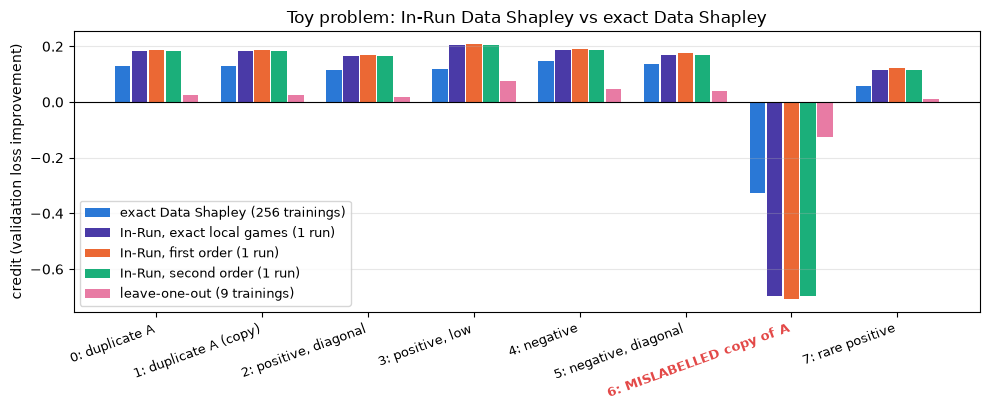

In [ ]:
toy_params0 = [(t.zeros(2, 1), t.zeros(1))]
toy_schedule = [t.arange(8)] * TOY_STEPS
toy_run = run_in_run_shapley(toy_params0, TOY_X, TOY_Y, TOY_VAL_X, TOY_VAL_Y, toy_schedule, TOY_LR, exact_local=True)

w_ref, b_ref = train_on_subset(TOY_X, TOY_Y, frozenset(range(8)))
t.testing.assert_close(toy_run["params"][0][0].squeeze(-1), w_ref)
t.testing.assert_close(toy_run["params"][0][1].squeeze(-1), b_ref)

print(f"actual improvement L(theta_0) - L(theta_T) = {toy_run['losses'][0] - toy_run['losses'][-1]:.4f}  (= v(D) = {toy_table[full]:.4f})")
for name, key in [("exact local", "exact"), ("first order", "first"), ("second order", "second")]:
    values = toy_run[key]
    r = np.corrcoef(values, toy_exact)[0, 1]
    print(f"In-Run, {name:<13} total {values.sum():.4f}   correlation with exact Data Shapley {r:.3f}")
display(
    pd.DataFrame(
        {"exact Data Shapley": toy_exact, "In-Run, exact local": toy_run["exact"], "In-Run, first order": toy_run["first"],
         "In-Run, second order": toy_run["second"], "leave-one-out": toy_loo},
        index=[f"{i}: {name}" for i, name in enumerate(TOY_NAMES)],
    ).round(4)
)

utils.plot_value_bars(
    {
        "exact Data Shapley (256 trainings)": toy_exact,
        "In-Run, exact local games (1 run)": toy_run["exact"],
        "In-Run, first order (1 run)": toy_run["first"],
        "In-Run, second order (1 run)": toy_run["second"],
        "leave-one-out (9 trainings)": toy_loo,
    },
    [f"{i}: {name}" for i, name in enumerate(TOY_NAMES)],
    "Toy problem: In-Run Data Shapley vs exact Data Shapley",
    colors=[utils.COLORS[k] for k in ["data_shapley", "exact_local", "first", "second", "loo"]],
    highlight=[6],
)

<details>
<summary>Expected output (printed part)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">actual improvement L(theta_0) - L(theta_T) = 0.5082  (= v(D) = 0.5082)
In-Run, exact local   total 0.5082   correlation with exact Data Shapley 0.994
In-Run, first order   total 0.5334   correlation with exact Data Shapley 0.994
In-Run, second order  total 0.5079   correlation with exact Data Shapley 0.994

                          exact Data Shapley  In-Run, exact local  In-Run, first order  In-Run, second order  leave-one-out
0: duplicate A                        0.1309               0.1819               0.1875                0.1818         0.0250
1: duplicate A (copy)                 0.1309               0.1819               0.1875                0.1818         0.0250
2: positive, diagonal                 0.1164               0.1652               0.1706                0.1651         0.0177
3: positive, low                      0.1175               0.2038               0.2080                0.2037         0.0741
4: negative                           0.1480               0.1862               0.1921                0.1861         0.0476
5: negative, diagonal                 0.1352               0.1695               0.1751                0.1694         0.0382
6: MISLABELLED copy of A             -0.3278              -0.6969              -0.7084              -0.6964        -0.1266
7: rare positive                      0.0572               0.1166               0.1209                0.1165         0.0096</pre>

</details>

<details>
<summary>Help - how should I interpret this plot?</summary>

First, the sanity checks. The accountant reproduces `train_on_subset` exactly, and the exact local values add up to 0.5082, which is both the actual improvement of the run and $v(D)$. On this gently-trained problem (small steps, 40 of them), the Taylor approximations are good: first order allocates 5% too much in total, second order is within 0.001.

**In-Run values are not Data Shapley values.** All three In-Run variants have a correlation of 0.994 with exact Data Shapley, and they agree on the big picture: the duplicates are tied, the mislabelled point is at the bottom, and the rare positive is the least valuable helpful point. But the correlation is dominated by that one outlier. Among the seven helpful points the orderings differ (point 3 is the most valuable for In-Run, but fifth for Data Shapley), and the magnitudes are very different: In-Run gives the mislabelled point -0.70, more than twice its Data Shapley value of -0.33, and correspondingly more to every helpful point, since both allocations add up to the same 0.508.

Why? In-Run Data Shapley accounts for *one* trajectory: the full-data run. In that run, point 6 trains alongside its two correctly-labelled copies at every step, and at every step its gradient points in exactly the opposite direction to theirs. The accountant books each push separately: the copies' pushes as helpful, point 6's push as harmful, step after step. Data Shapley instead averages over all the sub-datasets point 6 could have been part of, and in many of those the conflict simply cancels out (recall that $v(\{0, 6\}) = 0$). Neither answer is wrong. They're answers to different questions: "what did each example do during this run?" versus "how much is each example worth to this learning algorithm, on average over the data it could have been trained with?"

Leave-one-out, again, gets the signs right and the scale wrong.
</details>

## Validation 2: does the credit add up on the digits?

Now the real training run: the seed-0 digits model, 128 SGD steps with minibatches of 4. We compute all three kinds of credit (the exact local games have 16 coalitions per step). We'll also run each of the three training seeds, and for each one a **control**: the same training run, but with credit computed against a validation set whose labels have been randomly shuffled. Since the validation set never affects training, the trajectory is identical; only the question we ask of it changes. Credit for a meaningless target shouldn't pick out anything meaningful.

In [ ]:
in_run, in_run_shuffled = {}, {}
t0 = time.time()
for seed in tqdm(SEEDS):
    p0, schedule = init_mlp(SIZES, seed), make_schedule(N_TRAIN, BATCH_SIZE, EPOCHS, seed)
    in_run[seed] = run_in_run_shapley(p0, train_x, train_y, val_x, val_y, schedule, LR, exact_local=True)
    shuffled_val_y = val_y[t.randperm(len(val_y), generator=t.Generator().manual_seed(100 + seed))]
    in_run_shuffled[seed] = run_in_run_shapley(p0, train_x, train_y, val_x, shuffled_val_y, schedule, LR)
print(f"6 accounted training runs in {time.time() - t0:.1f}s")

run = in_run[0]
t.testing.assert_close(run["params"][0][0], trained[0][0])  # the accountant didn't change the training run
actual = run["losses"][0] - run["losses"][-1]
print(f"\nseed 0: validation loss {run['losses'][0]:.4f} -> {run['losses'][-1]:.4f}, actual improvement {actual:.4f}")
for name in ["exact", "first", "second"]:
    print(f"  total credit, {name:<7}: {run[name].sum():.4f}  ({run[name].sum() / actual:.2f}x the actual improvement)")
control = in_run_shuffled[0]
print(f"control: loss on the shuffled-label validation set goes {control['losses'][0]:.4f} -> {control['losses'][-1]:.4f}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">6 accounted training runs in 0.7s

seed 0: validation loss 0.7370 -> 0.1259, actual improvement 0.6111
  total credit, exact  : 0.6111  (1.00x the actual improvement)
  total credit, first  : 1.5547  (2.54x the actual improvement)
  total credit, second : 0.6089  (1.00x the actual improvement)
control: loss on the shuffled-label validation set goes 0.6805 -> 1.5256</pre>

</details>


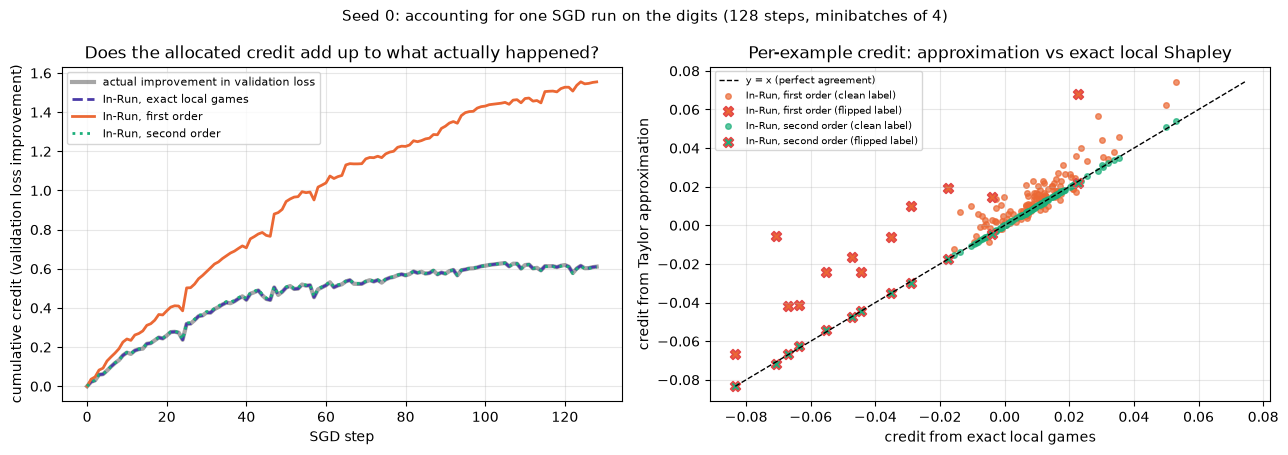

In [ ]:
actual_curve = (run["losses"][0] - run["losses"]).numpy()
utils.plot_accounting(
    {
        "actual improvement in validation loss": actual_curve,
        "In-Run, exact local games": np.concatenate([[0], run["exact_per_step"].sum(1).cumsum(0).numpy()]),
        "In-Run, first order": np.concatenate([[0], run["first_per_step"].sum(1).cumsum(0).numpy()]),
        "In-Run, second order": np.concatenate([[0], run["second_per_step"].sum(1).cumsum(0).numpy()]),
    },
    {"In-Run, first order": (run["exact"], run["first"]), "In-Run, second order": (run["exact"], run["second"])},
    flipped,
    "Seed 0: accounting for one SGD run on the digits (128 steps, minibatches of 4)",
)
for name in ["first", "second"]:
    print(f"correlation of {name}-order with exact local credit: {np.corrcoef(run[name], run['exact'])[0, 1]:.4f}")

<details>
<summary>Help - how should I interpret these plots?</summary>

**Left.** The exact local credit (dashed purple) lies exactly on the actual improvement in validation loss (thick grey): the per-step games telescope, so every bit of improvement, including the steps where validation loss went *up*, is accounted for. The second-order credit (dotted green) is indistinguishable at this scale: it allocates 0.609 of the actual 0.611. First-order credit (orange) climbs much faster than the real curve: by the end of training it has allocated 1.55, 2.54 times the improvement that actually happened.

**Right.** Per example, second-order credit is almost exactly the exact local credit (correlation 0.9999; the green points sit on the diagonal). First-order credit is systematically too high for the clean-label examples, and much more scattered for the flipped ones (correlation 0.86): several flipped images whose exact credit is clearly negative get a first-order total near zero or above it. One flipped image even ends with a *positive* exact credit; we'll see where that comes from in the next plot.

So with our learning rate, first-order In-Run credit is a badly calibrated accountant, and its errors land on exactly the examples we care most about. The second-order correction fixes it, at the price of one Hessian-vector product per step.
</details>

<details>
<summary>Question - the first-order method overcounts so badly. Why is the paper happy with it?</summary>

The size of the second-order correction relative to the first-order term scales like $\eta\, \|H_{val}\|\, \|\sum_j g_j\|$, i.e. like the size of a step relative to the curvature. Our learning rate of 0.1 on raw pixel inputs takes large steps for such a small model: even on the very first step, the first-order prediction of the improvement (0.036) is 60% larger than what the step actually achieves (0.0225). Language-model pretraining uses tiny learning rates and many more steps, where each step changes the loss very little and the first-order approximation is much better. The paper reports that, for GPT-2, its first-order values closely match Monte Carlo estimates of the per-iteration games (Section 5.2), and its analysis of negatively-valued pretraining data uses second-order values, whose ghost implementation costs roughly twice as much as first-order (Table 1). You can see the effect of the learning rate directly in the "Try it yourself" cell below.

There's a deeper point too. Efficiency is a property of a *game*. The first-order method allocates its approximate game perfectly; it's the game that doesn't match reality. So "the values add up" is not, by itself, evidence that an attribution method is right: you have to check what they add up *to*.
</details>

## When does an example earn its credit?

Since we recorded the credit at every step, we can follow each training example's running total through the run. Each example is visited once per epoch, so each line moves four times.


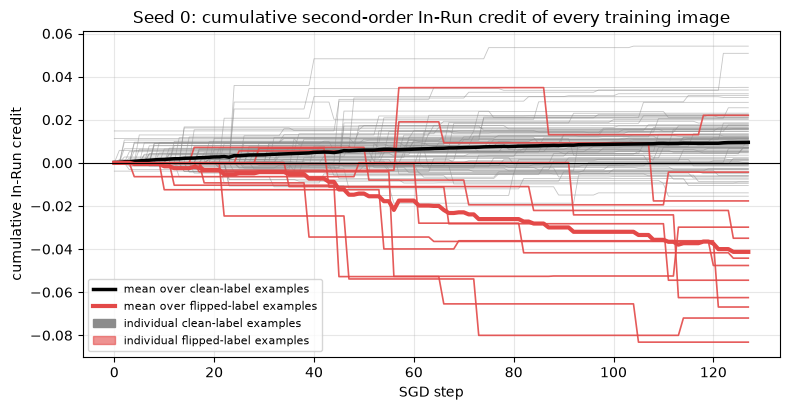

In [ ]:
utils.plot_credit_trajectories(
    run["second_per_step"].cumsum(0), flipped,
    "Seed 0: cumulative second-order In-Run credit of every training image",
)
epoch_credit = run["second_per_step"].reshape(EPOCHS, -1, N_TRAIN).sum(1)  # (epoch, example)
for epoch in range(EPOCHS):
    print(f"epoch {epoch}: total credit to clean examples {epoch_credit[epoch, ~flipped].sum():+.4f}, to flipped {epoch_credit[epoch, flipped].sum():+.4f}")

<details>
<summary>Help - how should I interpret this plot?</summary>

The average clean-label image (black) earns credit steadily, while the average flipped-label image (thick red) loses it, ending around -0.04. The per-epoch totals printed below the plot show *when*. In the first epoch the flipped images cost only -0.05 in total, while the clean ones earn +0.45: the network can barely tell 1s from 7s yet, so a mislabelled image is no worse than a slightly noisy one. The damage peaks in the second epoch (-0.19), once the model has learned enough that a 1 labelled '7' pushes clearly in the wrong direction, and tails off after that (-0.15, -0.11) as the model's predictions settle. The clean images' credit falls every epoch (+0.45, +0.31, +0.22, +0.12): the easy improvements come first.

The individual lines are jumpy, because an example earns all of a visit's credit in a single step, and the amount depends on the state of the model at that moment. One flipped image jumps to about +0.035 just before step 60 and only partly loses it later; that's the flipped image with positive total credit from the previous plot. A single visit can be useful even for a mislabelled image, if its push happens to point in a helpful direction at that moment (for instance, pulling the logit back after the model has overshot). This is what "credit for this run" means: the same image, visited at a different time, would have earned different credit.
</details>

## Do the lowest-credit examples have flipped labels?

The natural use of a data valuation is to look at the bottom of the ranking. We know which 12 examples are flipped, so for each seed and each kind of credit we count how many of them are among the 12 lowest-credit examples. Two controls: credit computed against shuffled validation labels, and a random ranking (which finds $12 \times 12 / 128 \approx 1.1$ flipped examples on average).

In [ ]:
def count_flipped_in_lowest(scores: Tensor, k: int = 12) -> int:
    """How many of the k lowest-scoring training examples have flipped labels?"""
    return flipped[scores.argsort()[:k]].sum().item()

In [ ]:
detection = pd.DataFrame(
    {
        seed: {
            "In-Run, exact local": count_flipped_in_lowest(in_run[seed]["exact"]),
            "In-Run, first order": count_flipped_in_lowest(in_run[seed]["first"]),
            "In-Run, second order": count_flipped_in_lowest(in_run[seed]["second"]),
            "control: second order, shuffled validation labels": count_flipped_in_lowest(in_run_shuffled[seed]["second"]),
            "control: random ranking (expected)": 12 * 12 / 128,
        }
        for seed in SEEDS
    }
).rename(columns=lambda s: f"seed {s}")
display(detection.round(1))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                                                   seed 0  seed 1  seed 2
In-Run, exact local                                  10.0    11.0    11.0
In-Run, first order                                   8.0    10.0     8.0
In-Run, second order                                 10.0    11.0    11.0
control: second order, shuffled validation labels     0.0     0.0     0.0
control: random ranking (expected)                    1.1     1.1     1.1</pre>

Exact-local and second-order credit put 10 or 11 of the 12 flipped images among the 12 lowest-credit examples, in every seed. First-order credit finds 8, 10 and 8, consistent with the scatter plot above: its errors are largest on the flipped examples. Both controls fail, as they should: a random ranking finds 1.1 on average, and credit computed against shuffled validation labels finds none at all. "None at all" is actually *worse* than random, which is suspicious for a control that's supposed to carry no information. We'll come back to this in section 5️⃣.
</details>

## Try it yourself - how big a step can a Taylor expansion take?

The first-order approximation should get better as the learning rate shrinks, and worse as it grows. Test that: for a range of learning rates, run the accountant on seed 0 (with the same number of steps), and plot the total credit each method allocates divided by the actual improvement. A perfect accountant sits at 1.

Things to try once you've seen the default output:

- Is there a learning rate where even the second-order method breaks down? What happens to the training run itself there?
- Instead of the learning rate, change the batch size (e.g. 2 or 8, adjusting `epochs` so the number of steps stays reasonable). With bigger batches, there are more interactions between examples in each local game. Does the first-order error grow?
- Compare the *rankings* rather than the totals (e.g. `np.corrcoef(run["first"], run["exact"])`). Can a method be badly calibrated but still rank well?


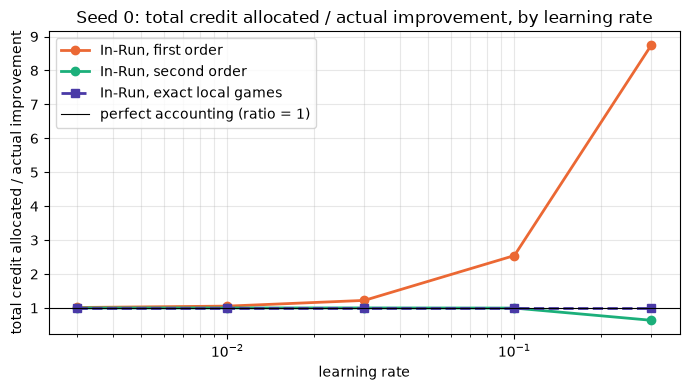

In [ ]:
TRY_LRS = [0.003, 0.01, 0.03, 0.1, 0.3]
ratios = {"In-Run, first order": [], "In-Run, second order": [], "In-Run, exact local games": []}
for lr in TRY_LRS:
    result = run_in_run_shapley(params0, train_x, train_y, val_x, val_y, schedule0, lr, exact_local=True)
    improvement = (result["losses"][0] - result["losses"][-1]).item()
    for name, key in [("In-Run, first order", "first"), ("In-Run, second order", "second"), ("In-Run, exact local games", "exact")]:
        ratios[name].append(result[key].sum().item() / improvement)
    print(f"lr {lr:<6} improvement {improvement:.4f}  first/actual {ratios['In-Run, first order'][-1]:.3f}  second/actual {ratios['In-Run, second order'][-1]:.3f}")
utils.plot_lr_balance(TRY_LRS, ratios, "Seed 0: total credit allocated / actual improvement, by learning rate")

<details>
<summary>Expected output (printed part)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">lr 0.003  improvement 0.0728  first/actual 1.013  second/actual 1.000
lr 0.01   improvement 0.1961  first/actual 1.054  second/actual 1.000
lr 0.03   improvement 0.4399  first/actual 1.222  second/actual 1.001
lr 0.1    improvement 0.6111  first/actual 2.544  second/actual 0.996
lr 0.3    improvement 0.6253  first/actual 8.748  second/actual 0.636</pre>

As expected, the first-order error grows with the learning rate: 1% too much credit at learning rate 0.003, 5% at 0.01, 22% at 0.03, 2.5× at 0.1 and almost 9× at 0.3. The second-order credit is within half a percent of the truth up to 0.1, but breaks down at 0.3, where it allocates only 64% of the improvement. The exact local games are always exact, by construction.

Notice that at learning rate 0.3 the run improves the validation loss only marginally more than at 0.1 (0.625 vs 0.611) even though each step is three times larger: most steps overshoot and partly undo each other. That's precisely the regime in which Taylor expansions of a single step fail. Small steps, like those of large-model pretraining, are where first-order In-Run credit is a faithful accountant.
</details>

## Summary of 4️⃣

- In-Run Data Shapley splits a training run into one small cooperative game per step, whose players are the examples in the minibatch and whose payoff is that step's improvement in validation loss. The per-step values telescope, so the total credit equals the actual improvement of the run.
- Taylor-expanding each local game makes it cheap. To first order, an example's credit is $\frac{\eta}{B} g_i \cdot g_{val}$, computable with ghost dot products during the backward pass. The second-order correction needs one Hessian-vector product per step and accounts for curvature and for interactions inside the minibatch.
- On the toy problem, In-Run values rank the examples almost exactly like exact Data Shapley, but they are a different quantity: they gave the mislabelled point more than twice as much negative credit, because In-Run credit books every push and counter-push of the one full-data trajectory, while Data Shapley averages over sub-datasets in which much of that conflict cancels out.
- On the digits, with our learning rate, first-order credit overcounts the improvement by a factor of 2.5 and is noticeably worse at finding flipped labels than the second-order and exact-local credit, which agree with each other almost perfectly.

So far, though, we've only checked that the accountant is internally consistent. Whether its credit means anything about what the *data* did to the model is a separate question, and it's the subject of the last section.

# 5️⃣ Does the Credit Mean Anything?

> ##### Learning Objectives
>
> - Vectorise Monte Carlo Data Shapley over prefixes, and simulate truncation exactly from the results
> - Implement deletion experiments with matched random controls, and evaluate attribution methods by what deleting data actually does
> - Report where cheap and expensive methods agree, where they disagree, and which differences are real

In section 4️⃣ we checked the accountant against itself: exact local games against their Taylor approximations. That tells us the arithmetic is right. It doesn't tell us whether In-Run credit says anything true about the data, for two reasons:

1. **It's a different question from Data Shapley.** In-Run values are about one trajectory, with every local game starting from a checkpoint that all the data helped produce. Retraining-based Data Shapley is about what each example adds across many possible training sets. On the toy problem they agreed on the big picture, but there was really only one example to disagree about.
2. **Credit is not causation.** An example that "earned" credit in one run isn't necessarily one you'd want to keep. The test that matters for data curation is an intervention: *delete the data and retrain*.

So in this section we'll compute the expensive ground truth, Monte Carlo Data Shapley on the digits with thousands of real retrainings, and then run the experiment that matters: delete the examples each method ranks lowest (or highest), retrain, and measure the test loss, against matched random deletions.

## Training many models at once

Retraining-based Data Shapley on the digits uses the same learning algorithm as everything else in this notebook: the seed's initialisation and schedule, with the excluded examples switched off by a 0/1 `keep` mask (fixed denominator). One Monte Carlo ordering needs a model for each of its $n + 1 = 129$ prefixes. Rather than training them one after another, we train them as a batch of 129 independent networks, with the same forward and backward pass you wrote in section 3️⃣, plus a leading "model" dimension. This is bookkeeping rather than anything new, so we've written it for you, and the cell below checks that it agrees with your `sgd_train`.

In [ ]:
@t.no_grad()
def train_many(params: Params, x: Tensor, y: Tensor, schedule: list[Tensor], lr: float, keep: Float[Tensor, "K n"]) -> Params:
    """
    Trains K copies of the MLP at once, model k using only the examples with keep[k, i] == 1 (fixed denominator).
    Equivalent to [sgd_train(params, x, y, schedule, lr, keep[k]) for k in range(K)], but much faster.
    Returns params with a leading K dimension: W of shape (K, d_in, d_out), b of shape (K, d_out).
    """
    K = keep.shape[0]
    params = [(W.expand(K, *W.shape).clone(), b.expand(K, *b.shape).clone()) for W, b in params]
    for batch in schedule:
        xb, yb, batch_size = x[batch], y[batch], len(batch)
        layer_inputs, h = [], xb.expand(K, *xb.shape)
        for k, (W, b) in enumerate(params):  # forward pass: h has shape (K, batch, d)
            layer_inputs.append(h)
            h = h @ W + b[:, None, :]
            if k < len(params) - 1:
                h = t.tanh(h)
        d = (t.sigmoid(h) - yb[:, None]) * keep[:, batch, None]  # output gradient, masked per model
        new_params = [None] * len(params)
        for k in reversed(range(len(params))):  # backward pass + SGD update
            W, b = params[k]
            a = layer_inputs[k]
            new_params[k] = (W - lr * a.mT @ d / batch_size, b - lr * d.sum(1) / batch_size)
            if k > 0:
                d = (d @ W.mT) * (1 - a**2)
        params = new_params
    return params


@t.no_grad()
def many_losses(params: Params, x: Tensor, y: Tensor) -> Float[Tensor, " K"]:
    """Mean BCE loss of each of the K models in a batch of models."""
    h = x.expand(params[0][0].shape[0], *x.shape)
    for k, (W, b) in enumerate(params):
        h = h @ W + b[:, None, :]
        if k < len(params) - 1:
            h = t.tanh(h)
    return F.binary_cross_entropy_with_logits(h.squeeze(-1), y.expand(h.shape[0], -1), reduction="none").mean(-1)

In [ ]:
check_keep = (t.rand(3, N_TRAIN, generator=t.Generator().manual_seed(0)) > 0.3).double()
many = train_many(params0, train_x, train_y, schedule0, LR, check_keep)
for k in range(3):
    single = sgd_train(params0, train_x, train_y, schedule0, LR, keep=check_keep[k])
    for (W_many, b_many), (W, b) in zip(many, single):
        t.testing.assert_close(W_many[k], W)
        t.testing.assert_close(b_many[k], b)
print("train_many agrees with sgd_train")

## Monte Carlo Data Shapley on the digits

For each ordering, we build the 129 prefix masks, train all 129 models in one call, and record the utility of every prefix: $u_k = v(\text{first } k \text{ examples of the ordering})$. Everything Monte Carlo (and truncated Monte Carlo) needs is in those numbers.

### Exercise - Monte Carlo from prefix utilities

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `mc_from_prefix_utilities`. It takes the orderings, shape `(M, n)`, and the prefix utilities, shape `(M, n + 1)` (where `prefix_utilities[m, k]` is the utility of the first `k` examples of ordering `m`, so column 0 is the empty set and column `n` the full dataset), and returns:

- the Monte Carlo Shapley estimate, shape `(n,)`: the marginal contribution of the example in position $j$ of ordering $m$ is `prefix_utilities[m, j + 1] - prefix_utilities[m, j]`;
- the number of trainings used, not counting the empty and full sets (which only need training once): $M \cdot n$ without truncation.

With `tolerance > 0`, return what **truncated** Monte Carlo would have computed from the same orderings: the example in position $j$ gets zero if `abs(v_full - prefix_utilities[m, k]) < tolerance` for any $k \le j$ (once an ordering is truncated, it stays truncated), and the trainings for truncated positions are not counted. Since we trained every prefix anyway, this tells us exactly what TMC would have returned and how much it would have saved, without running it separately.

Try to write this without a Python loop over orderings.

In [ ]:
def mc_from_prefix_utilities(
    orderings: Int[Tensor, "M n"], prefix_utilities: Float[Tensor, "M n_plus_1"], tolerance: float = 0.0
) -> tuple[Float[Tensor, " n"], int]:
    """Returns the (truncated) Monte Carlo Shapley estimate and the number of trainings it needed."""
    raise NotImplementedError()


tests.test_mc_from_prefix_utilities(mc_from_prefix_utilities)

<details>
<summary>Hint</summary>

`prefix_utilities.diff(dim=1)` gives the marginals by position. To credit them to examples, scatter-add them into an `(n,)` tensor with `index_add_(0, orderings.flatten(), marginals.flatten())`. For truncation, a boolean "close" matrix of shape `(M, n)` followed by `.cumsum(dim=1) > 0` marks every position at or after the first truncation point.
</details>


<details><summary>Solution</summary>

```python
def mc_from_prefix_utilities(
    orderings: Int[Tensor, "M n"], prefix_utilities: Float[Tensor, "M n_plus_1"], tolerance: float = 0.0
) -> tuple[Float[Tensor, " n"], int]:
    """Returns the (truncated) Monte Carlo Shapley estimate and the number of trainings it needed."""
    M, n = orderings.shape
    marginals = prefix_utilities[:, 1:] - prefix_utilities[:, :-1]  # (M, n), by position in the ordering
    if tolerance > 0:
        v_full = prefix_utilities[:, -1:]
        close = (v_full - prefix_utilities[:, :-1]).abs() < tolerance  # truncate before adding position j?
        truncated = close.cumsum(dim=1) > 0
        marginals = marginals.masked_fill(truncated, 0.0)
        n_trainings = int((~truncated).sum())
    else:
        n_trainings = M * n
    totals = t.zeros(n).index_add_(0, orderings.flatten(), marginals.flatten())
    return totals / M, n_trainings
```
</details>

Now we run it: 200 orderings per seed, so $200 \times 128 = 25{,}600$ trainings per seed, plus leave-one-out (128 more trainings per seed) as a cheap baseline. This takes about half a minute in total on a CPU. We keep the per-ordering marginals so that we can estimate how noisy the result is.

In [ ]:
N_ORDERINGS = 200
mc_results, loo_results = {}, {}
t0 = time.time()
for seed in SEEDS:
    p0, schedule = init_mlp(SIZES, seed), make_schedule(N_TRAIN, BATCH_SIZE, EPOCHS, seed)
    loss_untrained = mlp_loss(p0, val_x, val_y)
    gen = t.Generator().manual_seed(1000 + seed)
    orderings = t.stack([t.randperm(N_TRAIN, generator=gen) for _ in range(N_ORDERINGS)])
    prefix_utilities = []
    for ordering in tqdm(orderings, desc=f"seed {seed}"):
        # keep[k, i] = 1 if example i is among the first k of the ordering
        position = t.empty(N_TRAIN, dtype=t.long)
        position[ordering] = t.arange(N_TRAIN)
        keep = (position[None, :] < t.arange(N_TRAIN + 1)[:, None]).double()
        prefix_utilities.append(loss_untrained - many_losses(train_many(p0, train_x, train_y, schedule, LR, keep), val_x, val_y))
    prefix_utilities = t.stack(prefix_utilities)
    mc_results[seed] = dict(orderings=orderings, prefix_utilities=prefix_utilities)
    mc_results[seed]["values"], _ = mc_from_prefix_utilities(orderings, prefix_utilities)
    # Leave-one-out: the full dataset, and the full dataset minus each example
    keep = t.ones(N_TRAIN + 1, N_TRAIN)
    keep[t.arange(1, N_TRAIN + 1), t.arange(N_TRAIN)] = 0.0
    utilities = loss_untrained - many_losses(train_many(p0, train_x, train_y, schedule, LR, keep), val_x, val_y)
    loo_results[seed] = utilities[0] - utilities[1:]
print(f"{3 * N_ORDERINGS * N_TRAIN:,} + {3 * (N_TRAIN + 1)} trainings in {time.time() - t0:.0f}s")

mc0 = mc_results[0]
v_full = mc0["prefix_utilities"][0, -1].item()
print(f"\nseed 0: v(D) = {v_full:.4f} (the In-Run accountant's total was {in_run[0]['exact'].sum():.4f}),  sum of MC values = {mc0['values'].sum():.4f}")
half_1, _ = mc_from_prefix_utilities(mc0["orderings"][:100], mc0["prefix_utilities"][:100])
half_2, _ = mc_from_prefix_utilities(mc0["orderings"][100:], mc0["prefix_utilities"][100:])
print(f"split-half correlation of the MC estimate (100 vs 100 orderings): {np.corrcoef(half_1, half_2)[0, 1]:.3f}")
for tolerance in [0.01, 0.02, 0.05]:
    values, n_trainings = mc_from_prefix_utilities(mc0["orderings"], mc0["prefix_utilities"], tolerance)
    print(f"truncated MC, tolerance {tolerance}: {1 - n_trainings / (N_ORDERINGS * N_TRAIN):.0%} of trainings saved, "
          f"max |change| in values {(values - mc0['values']).abs().max():.4f} (values range {mc0['values'].min():.4f} to {mc0['values'].max():.4f})")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">76,800 + 387 trainings in 23s

seed 0: v(D) = 0.6111 (the In-Run accountant's total was 0.6111),  sum of MC values = 0.6111
split-half correlation of the MC estimate (100 vs 100 orderings): 0.951
truncated MC, tolerance 0.01: 21% of trainings saved, max |change| in values 0.0040 (values range -0.0225 to 0.0135)
truncated MC, tolerance 0.02: 28% of trainings saved, max |change| in values 0.0052 (values range -0.0225 to 0.0135)
truncated MC, tolerance 0.05: 42% of trainings saved, max |change| in values 0.0066 (values range -0.0225 to 0.0135)</pre>

</details>

A few things to take from this. (The number of seconds will differ on your machine.)

- **Same pie, different slices.** $v(D)$, the improvement from training on all 128 images, is the same 0.6111 that the In-Run accountant allocated: it's the same training run. By efficiency, the Monte Carlo values add up to it exactly. So In-Run credit and Data Shapley are two complete allocations of the same total; the question is how differently they slice it.
- **The estimate is reasonably stable.** Two independent halves of 100 orderings each agree with a correlation of 0.951. We'll look at how stable it is on the *clean* examples alone below, since that turns out to matter.
- **Truncation helps less than on large datasets.** With a tolerance of 0.01 (1.6% of $v(D)$), truncated Monte Carlo would have skipped 21% of the trainings, but it would have changed some values by up to 0.004, compared with a total spread of values from -0.0225 to 0.0135. With 128 examples, the learning curve is still rising near the end of most orderings, so the tail of an ordering isn't negligible. Ghorbani & Zou's savings come from datasets with thousands of points, where it is.

### Exercise - rank correlation

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

When comparing attribution methods, we usually care whether they *rank* examples the same way more than whether their values have the same scale (In-Run and Data Shapley values are in the same units, but as we'll see, they live on quite different scales). Implement `spearman_correlation`: the Pearson correlation between the ranks of the two score vectors. You can assume there are no ties. (`x.argsort().argsort()` gives the rank of every entry.)

In [ ]:
def spearman_correlation(x: Float[Tensor, " n"], y: Float[Tensor, " n"]) -> float:
    """Spearman rank correlation (no ties)."""
    raise NotImplementedError()


tests.test_spearman_correlation(spearman_correlation)

<details><summary>Solution</summary>

```python
def spearman_correlation(x: Float[Tensor, " n"], y: Float[Tensor, " n"]) -> float:
    """Spearman rank correlation (no ties)."""
    rank_x, rank_y = x.argsort().argsort().double(), y.argsort().argsort().double()
    rank_x, rank_y = rank_x - rank_x.mean(), rank_y - rank_y.mean()
    return ((rank_x @ rank_y) / (rank_x.norm() * rank_y.norm())).item()
```
</details>

## In-Run vs Monte Carlo Data Shapley

Here is every training example of seed 0, plotted by its Monte Carlo Data Shapley value (25,600 trainings) against the score from each cheaper method.


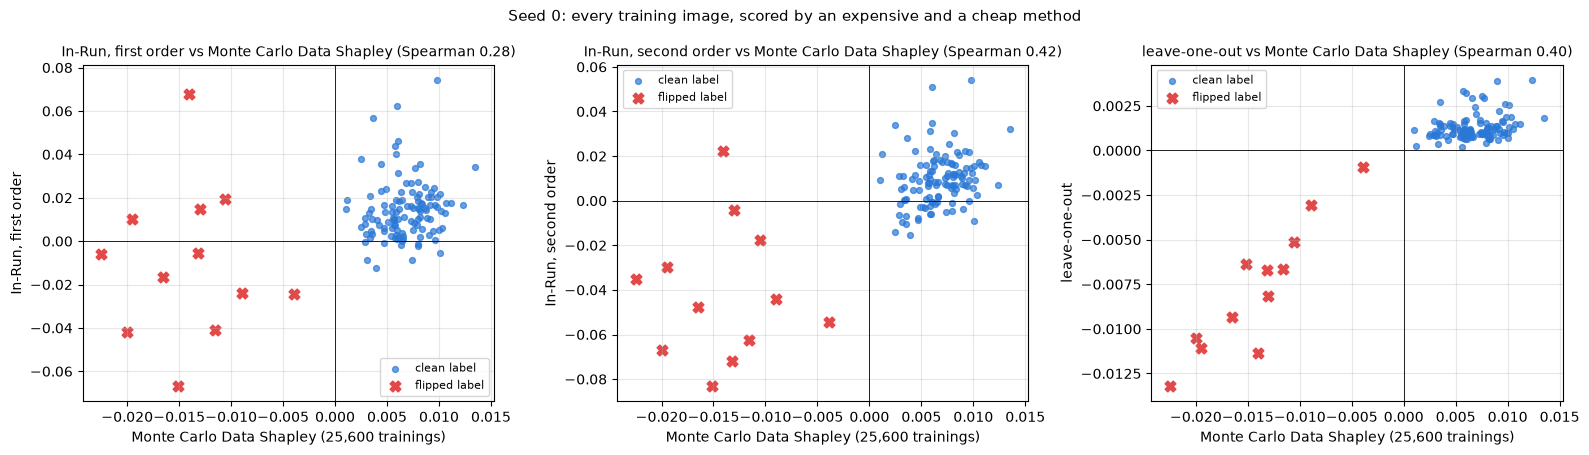

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, scores) in zip(
    axes,
    [("In-Run, first order", in_run[0]["first"]), ("In-Run, second order", in_run[0]["second"]), ("leave-one-out", loo_results[0])],
):
    rho = spearman_correlation(mc_results[0]["values"], scores)
    utils.plot_method_scatter(
        mc_results[0]["values"], scores, flipped, "Monte Carlo Data Shapley (25,600 trainings)", name,
        f"{name} vs Monte Carlo Data Shapley (Spearman {rho:.2f})", ax=ax,
    )
fig.suptitle("Seed 0: every training image, scored by an expensive and a cheap method", fontsize=11)
plt.tight_layout()
plt.show()

comparison = pd.DataFrame(
    {
        seed: {
            **{f"Spearman with MC Data Shapley: {name}": spearman_correlation(mc_results[seed]["values"], scores)
               for name, scores in [("In-Run 1st order", in_run[seed]["first"]), ("In-Run 2nd order", in_run[seed]["second"]),
                                    ("LOO", loo_results[seed]), ("shuffled-label control", in_run_shuffled[seed]["second"])]},
            **{f"flipped in lowest 12: {name}": count_flipped_in_lowest(scores)
               for name, scores in [("MC Data Shapley", mc_results[seed]["values"]), ("LOO", loo_results[seed]),
                                    ("In-Run 2nd order", in_run[seed]["second"]), ("In-Run 1st order", in_run[seed]["first"])]},
            # The same comparison restricted to the 116 clean-label examples, plus the MC estimate's own noise ceiling
            **{f"clean only, Spearman with MC: {name}": spearman_correlation(mc_results[seed]["values"][~flipped], scores[~flipped])
               for name, scores in [("In-Run 1st order", in_run[seed]["first"]), ("In-Run 2nd order", in_run[seed]["second"]),
                                    ("LOO", loo_results[seed])]},
            "clean only, MC split-half (100 vs 100 orderings)": spearman_correlation(
                *[mc_from_prefix_utilities(mc_results[seed]["orderings"][half], mc_results[seed]["prefix_utilities"][half])[0][~flipped]
                  for half in [slice(0, 100), slice(100, 200)]]
            ),
        }
        for seed in SEEDS
    }
).rename(columns=lambda s: f"seed {s}")
with pd.option_context("display.max_colwidth", 60, "display.width", 200):
    display(comparison.round(2))

<details>
<summary>Expected output (table)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                                                       seed 0  seed 1  seed 2
Spearman with MC Data Shapley: In-Run 1st order          0.28    0.22    0.37
Spearman with MC Data Shapley: In-Run 2nd order          0.42    0.37    0.62
Spearman with MC Data Shapley: LOO                       0.40    0.35    0.54
Spearman with MC Data Shapley: shuffled-label control   -0.54   -0.27   -0.47
flipped in lowest 12: MC Data Shapley                   12.00   12.00   11.00
flipped in lowest 12: LOO                               12.00   11.00   10.00
flipped in lowest 12: In-Run 2nd order                  10.00   11.00   11.00
flipped in lowest 12: In-Run 1st order                   8.00   10.00    8.00
clean only, Spearman with MC: In-Run 1st order           0.18   -0.03    0.28
clean only, Spearman with MC: In-Run 2nd order           0.28    0.15    0.49
clean only, Spearman with MC: LOO                        0.20    0.14    0.40
clean only, MC split-half (100 vs 100 orderings)         0.71    0.64    0.83</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

**Look at the left and right panels first.** Monte Carlo Data Shapley separates the two groups almost perfectly: in seed 0, every clean image has a positive value and every flipped image a negative one, and it puts 12, 12 and 11 of the flipped images in its lowest 12 across the three seeds. Leave-one-out tells exactly the same story (12, 11, 10), at 1/200th of the cost. For finding planted label noise in a dataset this small, you don't need Shapley values at all.

**Second-order In-Run credit** finds 10, 11 and 11 of the flipped images, about as many as LOO, from a single training run; first-order finds 8, 10 and 8. But the scatter plots show that In-Run credit spreads the examples out very differently. Clean examples' In-Run credit ranges up to 0.05-0.07, against at most 0.015 for Monte Carlo, and some clean images get negative In-Run credit. This is the tug-of-war effect from the toy problem again: In-Run books every push and counter-push of the one full-data run.

**On the 116 clean images, the methods mostly disagree.** Restricted to clean images, the Spearman correlation between second-order In-Run credit and Monte Carlo Data Shapley is 0.28, 0.15 and 0.49, and between LOO and Monte Carlo 0.20, 0.14 and 0.40. Is that just Monte Carlo noise? No: two independent halves of the Monte Carlo estimate agree with each other at 0.71, 0.64 and 0.83 on the same images (and the full 200-ordering estimate is more reliable than either half). The disagreement is real: the three methods rank clean images by genuinely different criteria, and for clean images, whose individual effects are small, those criteria don't line up.

**The shuffled-label control** is strongly *anti*-correlated with Monte Carlo Data Shapley (-0.54, -0.27, -0.47). We'll see why after the deletion experiment.
</details>

## The real test: delete and retrain

A data valuation is only useful if acting on it does what it says. So: for each method, remove the $k$ training examples with the **lowest** scores, retrain (same initialisation, same schedule, removed examples switched off), and measure the loss on the untouched **test** set. If low credit means harmful, test loss should go down. Then do the same for the $k$ **highest**-scoring examples, where test loss should go up.

There's one important subtlety, which is why we need a control. With a fixed denominator, removing *any* examples means less total gradient, so even removing random examples changes the test loss (usually it goes up a little, since the model trains less). So every curve is compared against removing $k$ **random** examples (10 random draws, matched in number). We also include the shuffled-validation-label control, and, as an oracle, removing exactly the 12 flipped examples.

### Exercise - removal masks

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Implement `removal_keep_masks`, which returns a `(len(ks), n)` tensor of 0/1 keep masks, where row `j` removes the `ks[j]` examples with the lowest scores (or the highest, if `lowest=False`). Row `j` should keep every other example.

In [ ]:
def removal_keep_masks(scores: Float[Tensor, " n"], ks: list[int], lowest: bool = True) -> Float[Tensor, "n_ks n"]:
    """Keep masks that remove the k lowest-scoring (or highest-scoring) examples, for each k in ks."""
    raise NotImplementedError()


tests.test_removal_keep_masks(removal_keep_masks)

<details><summary>Solution</summary>

```python
def removal_keep_masks(scores: Float[Tensor, " n"], ks: list[int], lowest: bool = True) -> Float[Tensor, "n_ks n"]:
    """Keep masks that remove the k lowest-scoring (or highest-scoring) examples, for each k in ks."""
    order = scores.argsort(descending=not lowest)
    keep = t.ones(len(ks), len(scores))
    for row, k in enumerate(ks):
        keep[row, order[:k]] = 0.0
    return keep
```
</details>

Now we run every deletion for every seed. Each seed needs (5 scorings × 2 directions + 10 random draws) × 8 values of $k$, plus the oracle: 161 retrainings, done in one `train_many` call. Remember that the scores were all computed from the validation set; the test set is used here for the first time.


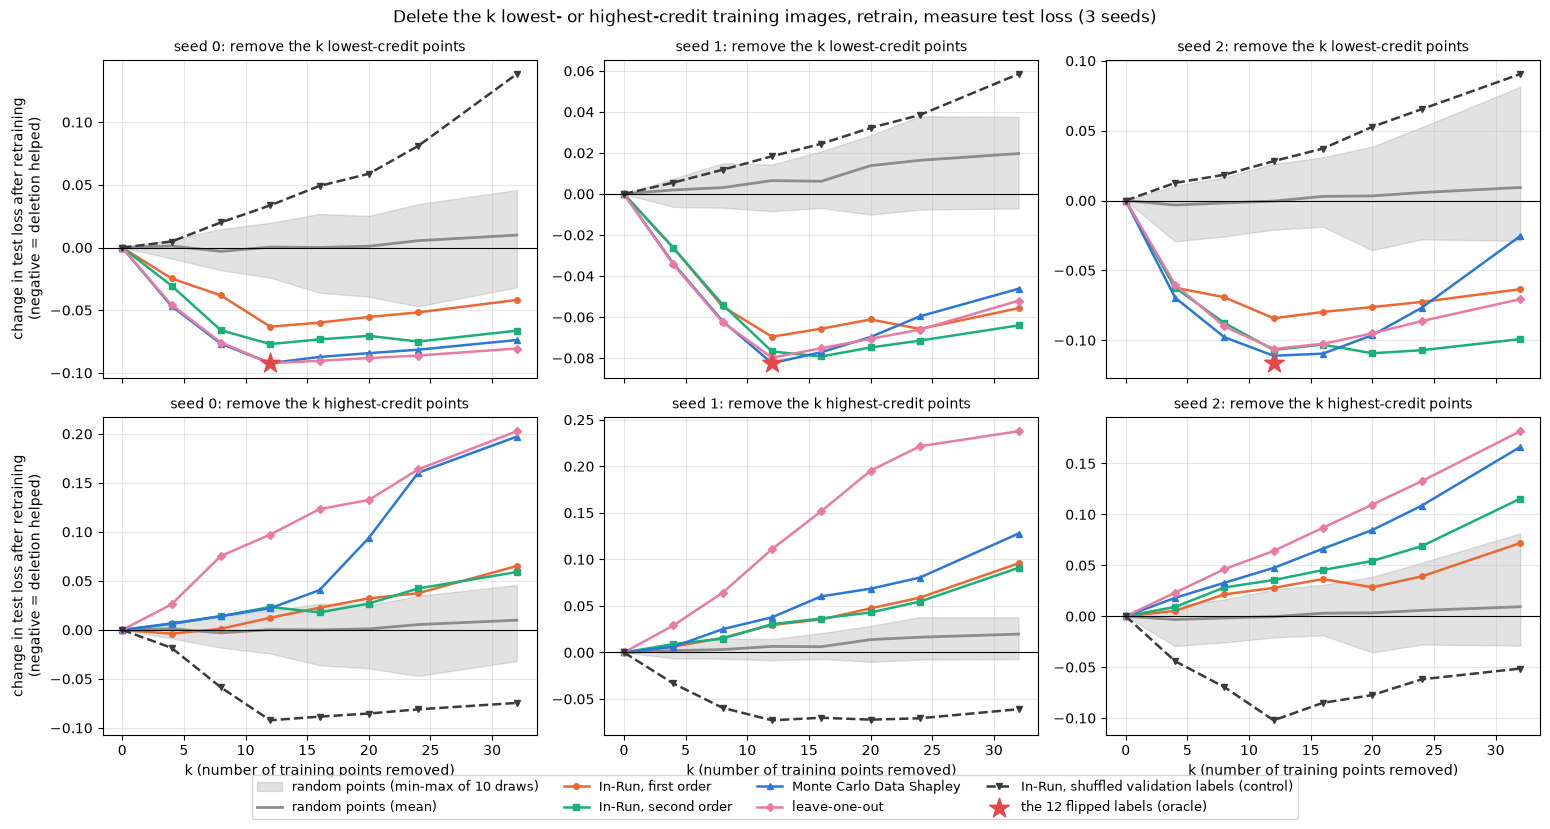

In [ ]:
KS = [0, 4, 8, 12, 16, 20, 24, 32]
N_RANDOM = 10
methods = {
    "In-Run, first order": lambda seed: in_run[seed]["first"],
    "In-Run, second order": lambda seed: in_run[seed]["second"],
    "Monte Carlo Data Shapley": lambda seed: mc_results[seed]["values"],
    "leave-one-out": lambda seed: loo_results[seed],
    "In-Run, shuffled validation labels (control)": lambda seed: in_run_shuffled[seed]["second"],
}
deletion, oracle = {}, {}
for seed in SEEDS:
    p0, schedule = init_mlp(SIZES, seed), make_schedule(N_TRAIN, BATCH_SIZE, EPOCHS, seed)
    names, masks = [], []
    for name, get_scores in methods.items():
        for which in ["lowest", "highest"]:
            names.append(f"{name}|{which}")
            masks.append(removal_keep_masks(get_scores(seed), KS, lowest=(which == "lowest")))
    gen = t.Generator().manual_seed(2000 + seed)
    for draw in range(N_RANDOM):
        names.append(f"random|{draw}")
        masks.append(removal_keep_masks(t.rand(N_TRAIN, generator=gen), KS))
    names.append("oracle")
    masks.append((~flipped).double()[None])
    test_losses = many_losses(train_many(p0, train_x, train_y, schedule, LR, t.cat(masks)), test_x, test_y)
    full_loss = test_losses[0].item()  # row 0 is k = 0: nothing removed
    changes = (test_losses - full_loss).split([len(m) for m in masks])
    deletion[seed] = {name: change.numpy() for name, change in zip(names, changes) if not name.startswith("random")}
    deletion[seed]["random"] = np.stack([change.numpy() for name, change in zip(names, changes) if name.startswith("random")])
    oracle[seed] = deletion[seed].pop("oracle")[0]

utils.plot_deletion_curves(
    KS, deletion, oracle, "Delete the k lowest- or highest-credit training images, retrain, measure test loss (3 seeds)"
)

Here are the numbers at $k = 12$ (the number of flipped labels), with the random baseline's mean and range:

In [ ]:
k_index = KS.index(12)
rows = {}
for seed in SEEDS:
    column = {f"remove lowest: {name}": deletion[seed][f"{name}|lowest"][k_index] for name in methods}
    column.update({f"remove highest: {name}": deletion[seed][f"{name}|highest"][k_index] for name in methods})
    random_12 = deletion[seed]["random"][:, k_index]
    column.update({"remove 12 random: mean": random_12.mean(), "remove 12 random: min": random_12.min(), "remove 12 random: max": random_12.max()})
    column["remove the 12 flipped (oracle)"] = oracle[seed]
    rows[f"seed {seed}"] = column
display(pd.DataFrame(rows).round(4))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                                                    seed 0  seed 1  seed 2
remove lowest: In-Run, first order                 -0.0631 -0.0696 -0.0843
remove lowest: In-Run, second order                -0.0770 -0.0768 -0.1069
remove lowest: Monte Carlo Data Shapley            -0.0922 -0.0824 -0.1111
remove lowest: leave-one-out                       -0.0922 -0.0798 -0.1062
remove lowest: In-Run, shuffled validation labe...  0.0336  0.0184  0.0282
remove highest: In-Run, first order                 0.0124  0.0295  0.0278
remove highest: In-Run, second order                0.0234  0.0304  0.0355
remove highest: Monte Carlo Data Shapley            0.0221  0.0377  0.0475
remove highest: leave-one-out                       0.0972  0.1109  0.0641
remove highest: In-Run, shuffled validation lab... -0.0922 -0.0729 -0.1022
remove 12 random: mean                              0.0004  0.0065 -0.0004
remove 12 random: min                              -0.0240 -0.0083 -0.0209
remove 12 random: max                               0.0197  0.0143  0.0261
remove the 12 flipped (oracle)                     -0.0922 -0.0824 -0.1164</pre>

</details>

<details>
<summary>Help - how should I interpret these results?</summary>

**Removing the lowest-credit examples (top row) works, for every method and every seed.** At $k = 12$, removing the 12 lowest-scoring images lowers test loss by 0.06-0.11, far outside the range of 10 random 12-image deletions (mean between -0.0004 and +0.0065, extremes -0.024 and +0.026). Monte Carlo Data Shapley and leave-one-out essentially match the oracle (in seed 0 both remove exactly the 12 flipped images, so their numbers are identical to the oracle's, -0.0922). Second-order In-Run credit recovers 83-93% of the oracle's improvement, and first-order 68-85%.

**Beyond $k = 12$, most of the curves turn back up.** Once the flipped images are gone, the next-lowest examples are clean ones, and deleting them costs something. The clearest case is Monte Carlo in seed 2, which goes from -0.111 at $k = 12$ to -0.025 at $k = 32$. A low score isn't a licence to delete: it's a ranking, and you still have to decide where to stop.

**Removing the highest-credit examples (bottom row) is where the methods differ most.** Leave-one-out's highest-scoring images are, by definition, the ones whose individual removal hurts the most, and removing 12 of them raises test loss by 0.06-0.11. Monte Carlo Data Shapley's highest hurt less (+0.022 to +0.048), and In-Run's least: +0.012 to +0.030 for first order, +0.023 to +0.036 for second order. In seed 0, removing the 12 highest first-order-credit images (+0.012) is within the range of removing 12 random images (up to +0.020), and removing the top 4 actually *lowers* the test loss slightly (by 0.004). So high In-Run credit is a weak guide to which examples you can't afford to lose. That's consistent with what In-Run measures: an example whose gradient did a lot of useful work in *this* run can often be replaced by other examples doing the same work in a run without it.

So, on this problem: for finding harmful data, second-order In-Run credit from one training run is nearly as good as 25,600 retrainings (and as leave-one-out's 129); first-order is noticeably worse. For finding the most valuable data, the retraining-based methods are clearly better.
</details>

<details>
<summary>Question - why does the shuffled-label control behave the way it does?</summary>

With the validation labels shuffled, the validation set asks the model to predict *random* labels for 1s and 7s. The best any model can do on that is to be unconfident. So as our model learns to tell 1s from 7s confidently, its loss on the shuffled validation set goes *up* (from 0.68 to 1.53 in seed 0; it's printed with the In-Run totals in section 4️⃣). The accountant faithfully books that: the clean images, which drive the learning, get negative credit, and the flipped images, which hold the model back, get positive credit. The shuffled-label credit is therefore anti-correlated with the real credit, and the deletion experiment shows it in both rows. Deleting its lowest-credit images removes useful clean data and makes the test loss *worse* than any random deletion (+0.034, +0.018, +0.028 at $k = 12$); deleting its *highest*-credit images removes the flipped labels and helps almost as much as the oracle.

The lesson is about what controls can and can't tell you. This control fails in the way that matters (its "harmful" examples aren't harmful), but it doesn't fail *randomly*, because a meaningless utility can still be systematically related to the real one. If you want a null for "is this ranking better than chance?", use matched random selections, as we did; the shuffled-label control answers a different question, "does the ranking depend on the validation target?" (yes, completely).
</details>

## Looking at the data

Numbers are one thing; let's look at the images. Below are the 8 lowest- and 8 highest-credit training images of seed 0, according to second-order In-Run Data Shapley. The title shows the label the model was trained on and the credit; a red border marks a flipped label.


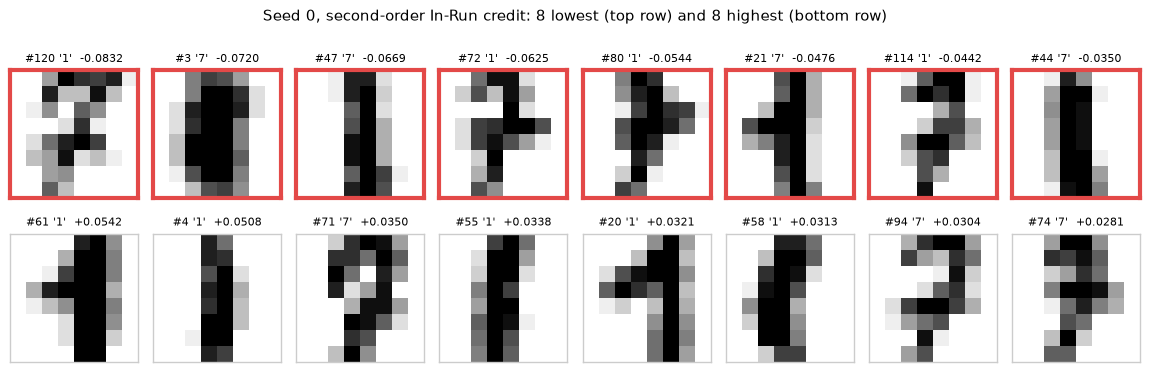

In [ ]:
scores = in_run[0]["second"]
order = scores.argsort()
shown = t.cat([order[:8], order.flip(0)[:8]])
utils.plot_digit_gallery(
    splits["train"]["images"][shown],
    [f"#{i} '{1 + 6 * int(train_y[i])}'  {scores[i]:+.4f}" for i in shown.tolist()],
    flipped[shown].tolist(),
    "Seed 0, second-order In-Run credit: 8 lowest (top row) and 8 highest (bottom row)",
    ncols=8,
)

<details>
<summary>Help - what should I notice?</summary>

All 8 of the lowest-credit images are flipped: four 1s labelled '7' and four 7s labelled '1'. Most of them are perfectly ordinary-looking digits, which is exactly what makes them harmful: the model has no way to treat them as exceptions.

All 8 of the highest-credit images are clean (five 1s and three 7s), and there's nothing obviously special about them: they're typical, clearly written digits. That fits the tug-of-war picture: in this run, the most valuable clean images may simply be the ones that happened to push back hardest against the flipped labels, which is a fact about the trajectory more than about the images. (That's a hypothesis, not something we've checked; the per-step credit matrix would let you test it.) Remember also, from the deletion experiment, that removing the highest-In-Run-credit images hurts only modestly more than removing random ones.
</details>

## What did each method cost?

Finally, the bill. We time one plain training run, one run with each kind of In-Run accounting, and the retraining-based methods, all for seed 0. Wall-clock times on a CPU with tiny tensors are dominated by Python overhead and depend on what else your machine is doing, so treat the seconds as rough. The number of *models trained* is the machine-independent cost.

In [ ]:
def timed(fn: Callable) -> float:
    start = time.perf_counter()
    fn()
    return time.perf_counter() - start


p0 = init_mlp(SIZES, 0)
one_ordering_keep = (t.arange(N_TRAIN)[None, :] < t.arange(N_TRAIN + 1)[:, None]).double()
costs = pd.DataFrame(
    [
        {"method": "plain SGD training run", "models trained": 1,
         "seconds": timed(lambda: sgd_train(p0, train_x, train_y, schedule0, LR))},
        {"method": "In-Run, first + second order", "models trained": 1,
         "seconds": timed(lambda: run_in_run_shapley(p0, train_x, train_y, val_x, val_y, schedule0, LR))},
        {"method": "In-Run, + exact local games", "models trained": 1,
         "seconds": timed(lambda: run_in_run_shapley(p0, train_x, train_y, val_x, val_y, schedule0, LR, exact_local=True))},
        {"method": "leave-one-out", "models trained": N_TRAIN + 1,
         "seconds": timed(lambda: train_many(p0, train_x, train_y, schedule0, LR, t.ones(N_TRAIN + 1, N_TRAIN)))},
        {"method": f"Monte Carlo Data Shapley ({N_ORDERINGS} orderings)", "models trained": N_ORDERINGS * N_TRAIN,
         "seconds": N_ORDERINGS * timed(lambda: train_many(p0, train_x, train_y, schedule0, LR, one_ordering_keep))},
    ]
).set_index("method")
display(costs.round(2))

<details>
<summary>Expected output (seconds will differ on your machine)</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">                                          models trained  seconds
method
plain SGD training run                                 1     0.01
In-Run, first + second order                           1     0.05
In-Run, + exact local games                            1     0.17
leave-one-out                                        129     0.04
Monte Carlo Data Shapley (200 orderings)           25600     7.19</pre>

On a CPU with a tiny model, every method is cheap in absolute terms, and the batched `train_many` makes 129 trainings (leave-one-out) take about as long as one accounted training run. That says more about tiny models and Python overhead than about the methods. Our In-Run implementation is also not optimised: it runs a separate backward pass for the validation set and an autograd Hessian-vector product at every step, so it's several times slower than plain training. The paper's ghost implementation on GPT-2 runs first-order In-Run Data Shapley at 93% of the throughput of regular training, and second-order at 45% (their Table 1).

The column that transfers to real models is "models trained". When one training run takes days or weeks, 129 runs are out of reach and 25,600 are absurd, while In-Run credit costs one run you were going to do anyway. Monte Carlo was also measured here by timing one ordering and multiplying by 200.
</details>

## Try it yourself - delete one image

Pick a training image, remove it, retrain seed 0, and compare the change in validation loss with what each method predicted. For a single example, "remove it and retrain" is exactly what leave-one-out measures, so this is a direct test of how well each method's score predicts a one-example intervention.

The cell below does this for the lowest- and highest-credit images and one flipped image. Try others:

- Which method's sign is most often right? Are there examples where every method agrees on the sign but the actual effect is the opposite?
- Removing one of 128 examples has a small effect. How does the size of that effect compare with the *noise* of the Monte Carlo estimate (its standard error is roughly the standard deviation of the per-ordering marginals divided by $\sqrt{200}$)?
- Use `run_in_run_shapley` on the retrained model (with the image switched off by giving it a different schedule, or a `keep` argument you add yourself) and compare the two credit trajectories. When do they start to diverge?

In [ ]:
seed0_scores = {"In-Run 1st": in_run[0]["first"], "In-Run 2nd": in_run[0]["second"], "MC Data Shapley": mc_results[0]["values"]}
TRY_EXAMPLES = [in_run[0]["second"].argmin().item(), in_run[0]["second"].argmax().item(), flipped.nonzero()[0].item()]

p0 = init_mlp(SIZES, 0)
full_val_loss = mlp_loss(sgd_train(p0, train_x, train_y, schedule0, LR), val_x, val_y).item()
for i in TRY_EXAMPLES:
    keep = t.ones(N_TRAIN)
    keep[i] = 0.0
    without_i = mlp_loss(sgd_train(p0, train_x, train_y, schedule0, LR, keep=keep), val_x, val_y).item()
    predictions = ", ".join(f"{name} {s[i]:+.4f}" for name, s in seed0_scores.items())
    print(f"#{i:<3} (flipped={bool(flipped[i])!s:<5}) actual effect of keeping it (LOO) {without_i - full_val_loss:+.4f} | {predictions}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">#120 (flipped=True ) actual effect of keeping it (LOO) -0.0064 | In-Run 1st -0.0669, In-Run 2nd -0.0832, MC Data Shapley -0.0151
#61  (flipped=False) actual effect of keeping it (LOO) +0.0019 | In-Run 1st +0.0743, In-Run 2nd +0.0542, MC Data Shapley +0.0098
#3   (flipped=True ) actual effect of keeping it (LOO) -0.0067 | In-Run 1st -0.0055, In-Run 2nd -0.0720, MC Data Shapley -0.0132</pre>

For these three images, every method gets the *sign* of the effect right. The sizes are a different matter. Removing the lowest-credit image (#120) improves validation loss by only 0.0064, while second-order In-Run credit says -0.083, thirteen times more, and Monte Carlo Data Shapley says -0.015. That's the same pattern as the toy problem, now for harmful data. The other five flipped images of the same kind do much of the same damage whether or not #120 is there, so removing it alone changes little; Data Shapley averages over coalitions in which #120 does more of the damage on its own; and In-Run books the full force of every harmful push in the one run where all of them were present. Also note #3: first-order and second-order credit disagree by a factor of 13 for this image (-0.0055 vs -0.072), a reminder that the first-order errors are concentrated on the flipped examples.
</details>

## Summary of 5️⃣

- Monte Carlo Data Shapley on the digits (25,600 retrainings per seed) separates the 12 flipped labels from the clean data almost perfectly, and so does leave-one-out with 129 retrainings. Truncation would only have saved 20-40% of the trainings, with some bias.
- Second-order In-Run credit, from a single training run, puts 10-11 of the flipped images in its lowest 12, and deleting its lowest-scoring images recovers most of the improvement of deleting exactly the flipped ones. First-order credit is noticeably worse at both.
- The retraining-based methods and In-Run credit are allocations of the same total improvement, but they slice it very differently. On the clean images their rankings largely disagree, by more than Monte Carlo noise can explain; In-Run credit is much more spread out; and the highest-In-Run-credit images are not much more important to retraining than random ones.
- Every claim above was checked against matched random deletions. The shuffled-label control showed that a valuation depends completely on its validation target, and that a meaningless target can be *systematically* misleading rather than merely uninformative.

In-Run Data Shapley is a faithful accountant of one training run (exactly so, with exact or second-order local games). What that accounting means for decisions about data, like deletion, has to be tested separately, by actually retraining.

# ☆ Bonus

## In-Run Data Shapley under Adam

Everything in this notebook used plain SGD, and that was not an accident: the derivation leaned on the update being a *sum* of per-example gradients, $\Delta\theta_t = -\frac{\eta}{B}\sum_{i \in \mathcal{B}_t} g_{t,i}$. That's what made the local game well-defined (switch off an example, drop its term), the first-order game additive, and the ghost dot product applicable. Almost every real model is trained with Adam or AdamW, which breaks all three:

- **The update is not a sum over examples.** Adam divides the (momentum-averaged) gradient elementwise by $\sqrt{\hat v_t} + \epsilon$, where $\hat v_t$ is a running average of *squared* gradients, which itself depends on the current minibatch. Removing an example changes both the numerator and the denominator, so $U_t(S)$ is no longer a Taylor expansion in a sum of per-example terms.
- **Credit leaks across steps.** Through the momentum buffer $m_t = \beta_1 m_{t-1} + (1 - \beta_1)\bar g_t$, an example's gradient at step $s$ keeps contributing to the updates at steps $s+1, s+2, \dots$ with weight $\beta_1^{t-s}$. A per-step game that only includes the current minibatch misses this.
- **The ghost trick breaks.** Even if you freeze the preconditioner $P_t = \text{diag}(1/(\sqrt{\hat v_t} + \epsilon))$, the first-order credit becomes $g_{t,i}^\top P_t\, g_{val}$. For a layer's weight gradient $a_i^\top d_i$, this is $\sum_{p,q} a_{ip} d_{iq} P_{pq} a_{val,p} d_{val,q}$, which no longer factorises into two short dot products, because $P$ is an arbitrary elementwise scaling rather than a rank-one one.

Ding, Zhang, Wang & Hu ([*In-Run Data Shapley for Adam Optimizer*](https://arxiv.org/abs/2602.00329), 2026) study exactly this. They report that SGD-style In-Run proxies correlate poorly with true per-step contributions when training uses Adam (Pearson $R \approx 0.11$ in their experiments), and propose an Adam-aware variant: a **fixed-state approximation** that freezes Adam's internal state at each step to restore an additive utility with a closed-form solution, and a **linearised ghost approximation** of the variance-dependent scaling, so that the pairwise dot products can again be computed without materialising per-example gradients. They report near-perfect fidelity to ground-truth marginal contributions ($R > 0.99$) at about 95% of standard training throughput.

If you'd like to explore this yourself, here is a suggested sequence, all on the digits:

1. Train with `t.optim.Adam`-style updates written out by hand (you'll need $m_t$, $v_t$ and the bias corrections), using the same schedule.
2. Define the local game with Adam's state **frozen** at $(m_{t-1}, v_{t-1})$ and with the current batch's gradient entering only through $m_t$ (i.e. treat the preconditioner as a constant). Compute its exact Shapley values by brute force, as in section 4️⃣.
3. Compare against (a) the SGD first-order formula $\frac{\eta}{B} g_i \cdot g_{val}$ applied naively, and (b) the preconditioned version $g_i^\top P_t g_{val}$, computed with materialised gradients. How badly does (a) do? Does (b) recover the exact values?
4. How much credit does an example earn *after* the step where it was in the batch, through momentum? Is it enough to change the ranking?
5. Read the paper's linearised ghost approximation and implement it for our MLP. How close does it get to (b)?

## Other things to try

- **Early vs late credit.** The paper's GPT-2 case study found that general-purpose data contributes most early in training and domain-specific data later. We only looked at per-epoch totals for the flipped and clean groups. Use the `second_per_step` matrix to compare each *individual* example's credit in the first and last epoch. Are there clean examples that are helpful early and harmful late, or the other way round? What do they look like?
- **Proper retraining.** Our deletion experiments kept the schedule and denominator fixed, so deleting examples also reduced the total amount of training. Repeat them with "real" retraining (rebuild the minibatches from the remaining examples, divide by the actual batch size). Do the rankings still predict the effect of deletion? Does the random baseline still lose?
- **Anomaly hunt.** In seed 0, removing the 4 highest first-order-credit images *lowered* the test loss slightly, and removing the 12 highest was within the range of random deletions. Find the individual examples responsible: are they unusual images, examples that earned their credit in one large step, examples whose job is done just as well by others, or something else? Does the same happen for second-order credit?
- **Ranking at scale.** Our dataset is tiny. Repeat the flipped-label detection experiment on MNIST (60,000 images, 1-10% flipped labels) with a slightly larger MLP, where retraining-based Data Shapley is out of reach. Is first-order In-Run credit still worse than second-order? How does it compare with simply ranking examples by their final training loss, a classic and very cheap baseline?
- **Other semivalues.** Data Shapley weights every coalition size by the same total weight. Beta Shapley (Kwon & Zou, 2022) puts more weight on small coalitions, and Data Banzhaf (Wang & Jia, 2023) weights all subsets equally, which makes it more robust to the noise in the utility. Both are easy to estimate from the prefix utilities you already have. Do they find the flipped labels better than Data Shapley?
- **Sequences.** Extend the ghost dot product to a linear layer applied at every position of a sequence, $\sum_{t, t'} (a_{it} \cdot a_{jt'})(d_{it} \cdot d_{jt'})$, and use it to compute first-order In-Run credit for a tiny transformer (e.g. the one from [1.1]) trained on a toy task.

## Further reading

- Wang, Mittal, Song & Jia (ICLR 2025), [*Data Shapley in One Training Run*](https://arxiv.org/abs/2406.11011). In-Run Data Shapley, the ghost dot product and the ghost gradient-Hessian-gradient product, and case studies on GPT-2 pretraining data (data curation, how contribution changes over training, and the copyright implications of paraphrased training data). The authors' implementation of per-sample gradient similarities is [GhostSuite](https://github.com/Jiachen-T-Wang/GhostSuite).
- Ghorbani & Zou (ICML 2019), [*Data Shapley: Equitable Valuation of Data for Machine Learning*](https://arxiv.org/abs/1904.02868). Data Shapley and TMC-Shapley.
- Jia et al. (AISTATS 2019), [*Towards Efficient Data Valuation Based on the Shapley Value*](https://arxiv.org/abs/1902.10275). Sampling estimators and their sample complexity, and exact values for nearest-neighbour models.
- Ding, Zhang, Wang & Hu (2026), [*In-Run Data Shapley for Adam Optimizer*](https://arxiv.org/abs/2602.00329). Discussed above.
- Pruthi, Liu, Kale & Sundararajan (NeurIPS 2020), [*Estimating Training Data Influence by Tracing Gradient Descent*](https://arxiv.org/abs/2002.08484). TracIn, the checkpoint-based cousin of first-order In-Run credit; covered in [16.10].
- Li, Tramèr, Liang & Hashimoto (ICLR 2022), [*Large Language Models Can Be Strong Differentially Private Learners*](https://arxiv.org/abs/2110.05679). Ghost clipping, which uses the same factorisation to compute per-example gradient *norms* for differentially private training (building on Goodfellow's 2015 note on [efficient per-example gradient computations](https://arxiv.org/abs/1510.01799)).
- Kwon & Zou (AISTATS 2022), [*Beta Shapley*](https://arxiv.org/abs/2110.14049), and Wang & Jia (AISTATS 2023), [*Data Banzhaf*](https://arxiv.org/abs/2205.15466). Alternative semivalues for data valuation.
- Ilyas et al. (ICML 2022), [*Datamodels: Predicting Predictions from Training Data*](https://arxiv.org/abs/2202.00622). A regression-based approach to the same "what if we'd trained on a subset?" question; covered in [16.11].